# Домашнее задание 1: Градиентный спуск и знакомство с PyTorch

### Оценивание и штрафы

Максимально допустимая оценка за работу — 10 баллов и высчитывается по формуле min{10; ваш балл}. Сдавать задание после указанного срока сдачи нельзя. 

**Дедлайны:**

- Мягкий дедлайн: 2 недели от даты выдачи.

- Жесткий дедлайн: 3 недели от даты выдачи.

- Штрафа за просрочку после мягкого дедлайна нет.

- Работы, присланные позже жесткого дедлайна, не принимаются.

**Плагиат и Оценивание**

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов. Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо оформленные графики. Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

Ответы на вопросы в ноутбуке (поле «Ваш ответ») обязательны: задание без ответа на относящийся к нему вопрос не принимается.

**Защиты**

Итоговая оценка за ДЗ зависит от результатов устной защиты работы проверяющему. Защищаются только те задания, которые были сделаны ДЗ, и теория, необходимая для их реализации. 

### Общая информация
Цели работы:
1. Повторим базу и напишем своими руками градиентный спуск и его модификации (SGD, Momentum).
2. Познакомимся с PyTorch: тензоры, автоматическое дифференцирование (autograd) и первый цикл обучения модели.

Структура и баллы:
- **Часть 1. Градиентный спуск** — 6 баллов (+ бонусы)
- **Часть 2. Знакомство с PyTorch** — 4 балла

Полезные материалы будут сопровождать вас по ходу работы.

**Дисклеймер:**

Если скелет вас только пугает, сбивает и т.д., вы можете его убрать и написать всё самостоятельно с нуля. Главное $-$ придерживаться условия заданий.

# Часть 1. Градиентный спуск (6 баллов)

В этом задании две части $-$ теоретическая и практическая. Теорию можно набирать, используя LaTex, или просто решать на листочке, сфотографировать и отправить вместе с заполненным ноутбуком.

## Теория (1.5 балла)

**Напоминание**: градиентный спуск — метод оптимизации, основанный на том, что отрицательный градиент указывает направление наибольшего убывания функции. Для функции $f(x)$ одношаговый градиентный спуск выглядит как:

$$x_{t+1} = x_t - \eta \nabla f(x_t)$$

Где $\eta$ — learning rate (шаг). Для многомерных функций аналогично.

**Полезные ссылки:**

- Bishop, "Pattern Recognition and Machine Learning" (глава о оптимизации).
- Краткое руководство: https://ml-cheatsheet.ru/gradient-descent/
- Официальный tutorial по оптимизации: https://pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html


### **Задание 1** (0.6 балла)
* Найдите экстремумы следующих функций (вручную, где возможно) и укажите их тип (максимум, минимум);
* Найдите точки перегиба функций (вручную, где возможно)

1) $f(x) = x^2 - 30x + 1$

2) $g(x) = -x^3 + 5x - 7x^2 + 17$

3) $h(x) = x^2 - 1/x$

4) $j(x) = 1/x^5 + x^{17} + 8$

---

**Краткая справка: экстремумы и перегибы**

**Экстремумы (локальные максимумы и минимумы).**

Точка $x_0$ называется *критической*, если первая производная в ней равна нулю $f'(x_0) = 0$. Для функций нескольких переменных это точки, где все частные производные равны нулю.

Критические точки являются кандидатами на локальные экстремумы, но это не все такие точки:

- Если $f'(x_0) = 0$ и $f''(x_0) > 0$, то в $x_0$ — **локальный минимум**.  
- Если $f'(x_0) = 0$ и $f''(x_0) < 0$, то в $x_0$ — **локальный максимум**.  
- Если $f'(x_0) = 0$ и $f''(x_0) = 0$, требуется дополнительный анализ (возможно, **седловая точка** - является одновременно точкой локального максимума по одному направлению и точкой локального минимума по другому направлению).

> Соответственно, алгоритм поиска локальных экстремумов: ищем производную функции -> приравниваем к нулю, решаем уравнение и получаем критические точки -> проверяем знак производной (от этого зависит max/min) или используем вторую производную для проверки (если равно 0, нужно доп. исследование)

---

**Перегиб**

Пусть $a < b < c$. Пусть на промежутке $a < b$ функция $f$ выпукла, а на промежутке $b < c$ функция $f$ вогнута. Тогда точка $b$ называется **точкой перегиба** (то есть функция меняет знак выпуклости в этой точке). Пример: точка 0 является точкой перегиба для функции $f(x) = x^3$.

Необходимое условие точки перегиба для дважды дифференцируемой функции: $f′′(c) = 0$

То есть практически ищут точки, где $f''(x_0) = 0$, и проверяют изменение знака $f''$ по обе стороны от этой точки.  
Если знак действительно меняется, то в $x_0$ находится точка перегиба.


> Соответственно, алгоритм поиска точек перегиба: ищем вторую производную -> приравниваем нулю и решаем уравнение (либо получаем точки, где она не существует) -> проверяем смену знака


---

**Ваше решение:**

### **Задание 2** (0.6 балла)
Найдите экстремумы и точки перегиба этих функций в Python.

*Справка*:
> Sympy $-$ библиотека для символьных вычислений (математика "на бумаге", но в коде). Умеет в производные, интегралы, пределы, уравнения, матрицы, многочлены и т.д.

Пример запуска (функция $f(x) = x^2$):

In [1]:
import sympy as sp

# объявляем переменную
x = sp.Symbol('x')

# задаём функцию
f = x**2

# производная
f_prime = sp.diff(f, x)

# выводим результаты
print("f(x) =", f)
print("f'(x) =", f_prime)

f(x) = x**2
f'(x) = 2*x


Теперь переходим к решению ранее озвученного задания

In [15]:
import sympy as sp

x = sp.Symbol('x')

def solve_function(f, name="f"):
    print(f"\n{'='*52}")
    print(f"Функция: {name}(x) = {f}")

    f_prime = sp.diff(f, x)
    print(f"Первая производная: f'(x) = {f_prime}")

    crit_points = sp.solve(f_prime, x)
    crit_points = [p for p in crit_points if p.is_real]
    print(f"Критические точки: {crit_points}")

    f_prime_prime = sp.diff(f_prime, x)
    print(f"Вторая производная: f''(x) = {f_prime_prime}")

    print("\nПоиск экстремумов")
    for point in crit_points:
        value = f_prime_prime.subs(x, point)
        value_simple = sp.simplify(value)
        f_val = sp.simplify(f.subs(x, point))

        if value_simple.is_positive:
            type_ext = "Минимум"
        elif value_simple.is_negative:
            type_ext = "Максимум"
        else:
            type_ext = "Не определено"

        point_num = float(point.evalf())
        f_val_num = float(f_val.evalf())

        print(f"  x = {point}  ≈ {point_num:.4f}")
        print(f"    f''(x) = {value_simple}  ->  {type_ext}")
        print(f"    f(x) = {f_val}  ≈ {f_val_num:.4f}")

    print("\nПоиск точек перегиба")
    point_cand = sp.solve(f_prime_prime, x)
    point_cand = [p for p in point_cand if p.is_real]
    print(f"f''(x) = 0: {point_cand}")

    for i in point_cand:
        diff = 0.001
        left = float(f_prime_prime.subs(x, i - diff))
        right = float(f_prime_prime.subs(x, i + diff))

        if left * right < 0:
            f_val = sp.simplify(f.subs(x, i))
            print(f"  Точка перегиба: x = {i}, f(x) = {f_val}")
        else:
            print(f"  x = {i} знак не меняется")


f = x**2 - 30*x + 1
solve_function(f, "f")

g = -x**3 + 5*x - 7*x**2 + 17
solve_function(g, "g")

h = x**2 - 1/x
solve_function(h, "h")

j = 1/x**5 + x**17 + 8
solve_function(j, "j")


Функция: f(x) = x**2 - 30*x + 1
Первая производная: f'(x) = 2*x - 30
Критические точки: [15]
Вторая производная: f''(x) = 2

Поиск экстремумов
  x = 15  ≈ 15.0000
    f''(x) = 2  ->  Минимум
    f(x) = -224  ≈ -224.0000

Поиск точек перегиба
f''(x) = 0: []

Функция: g(x) = -x**3 - 7*x**2 + 5*x + 17
Первая производная: f'(x) = -3*x**2 - 14*x + 5
Критические точки: [-5, 1/3]
Вторая производная: f''(x) = -6*x - 14

Поиск экстремумов
  x = -5  ≈ -5.0000
    f''(x) = 16  ->  Минимум
    f(x) = -58  ≈ -58.0000
  x = 1/3  ≈ 0.3333
    f''(x) = -16  ->  Максимум
    f(x) = 482/27  ≈ 17.8519

Поиск точек перегиба
f''(x) = 0: [-7/3]
  Точка перегиба: x = -7/3, f(x) = -542/27

Функция: h(x) = x**2 - 1/x
Первая производная: f'(x) = 2*x + x**(-2)
Критические точки: [-2**(2/3)/2]
Вторая производная: f''(x) = 2 - 2/x**3

Поиск экстремумов
  x = -2**(2/3)/2  ≈ -0.7937
    f''(x) = 6  ->  Минимум
    f(x) = 3*2**(1/3)/2  ≈ 1.8899

Поиск точек перегиба
f''(x) = 0: [1]
  Точка перегиба: x = 1, f(x) = 0


### Задание 3 (0.3 балла)
Постройте графики вышеупомянутых функций (не забудьте подписать оси и сами графики):
*   изобразите графики с подписанными осями
*   отметьте одним цветом локальные экстремумы
*   отметьте другим цветом точки перегиба
*   подпишите на оси x значения экстремумов и точек перегиба

Подсказка: для того, чтобы отметить точку на графике, вам понадобится функция (plt.scatter), а для того, чтобы подписать её значение на оси (plt.annotate).

Пример хорошего графика:

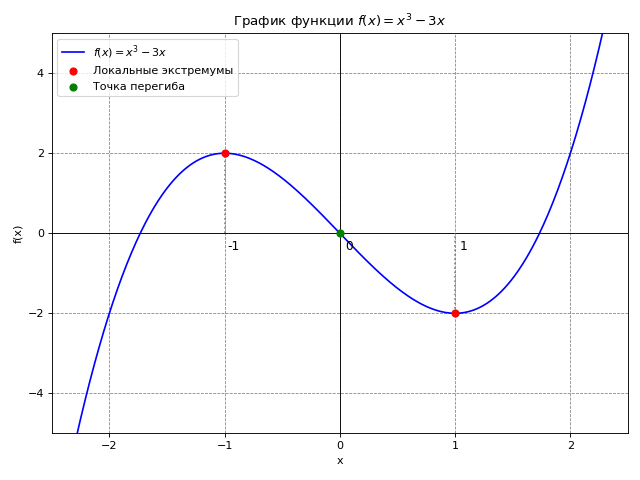

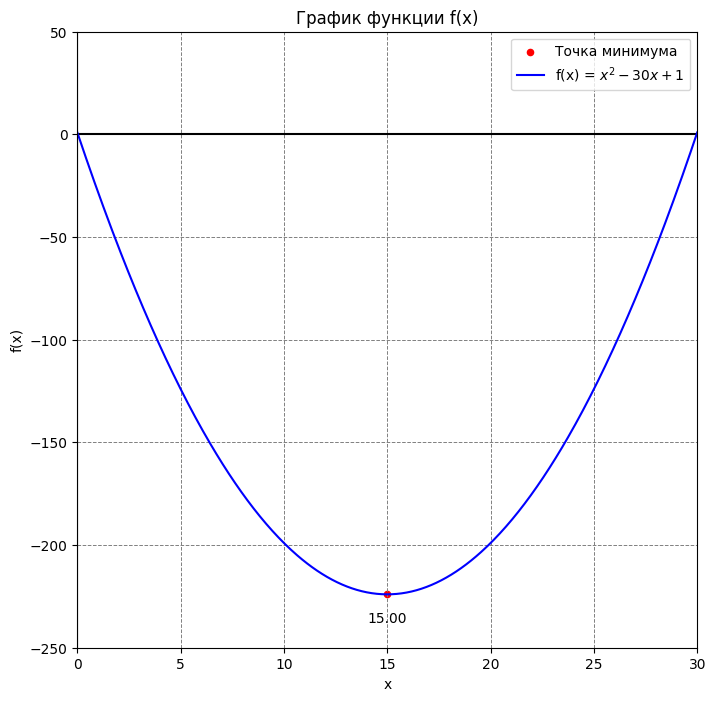

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Скелет для примера: заполните нужными значениями, а далее повторите с другими функциями.
# Функцию называем f_np, чтобы не перепутать её с sympy-выражениями из задания 2.

def f_np(x):
    return x**2 - 30*x + 1

# TODO: подберите диапазон по x так, чтобы были видны все особые точки
x_values = np.linspace(0, 30, 500)
y_values = f_np(x_values)

# TODO: координаты точки минимума, найденные в заданиях 1-2
x_min, y_min = 15, -224

# Создаём окно для графика
plt.figure(figsize=(8, 8))

# Рисуем координатные оси для наглядности
plt.axvline(x=0, c='black')
plt.axhline(y=0, c='black')
# Добавляем сетку для удобства чтения графика
plt.grid(color='gray', linestyle='--', linewidth=0.7)

# TODO: ограничьте диапазон отображаемых значений
plt.xlim(0, 30)
plt.ylim(-250, 50)

# Подписываем оси
plt.xlabel('x')
plt.ylabel('f(x)')

# Подписываем значение x-координаты минимума под точкой
plt.annotate(f'{x_min:.2f}', (x_min, y_min), textcoords="offset points", xytext=(0, -20), ha='center')
# Отмечаем на графике найденную точку минимума
plt.scatter(x_min, y_min, label='Точка минимума', color='red', s=20)

plt.title('График функции f(x)')
plt.plot(x_values, y_values, label='f(x) = $x^2 - 30x + 1$', color='blue')
plt.legend()
plt.show()



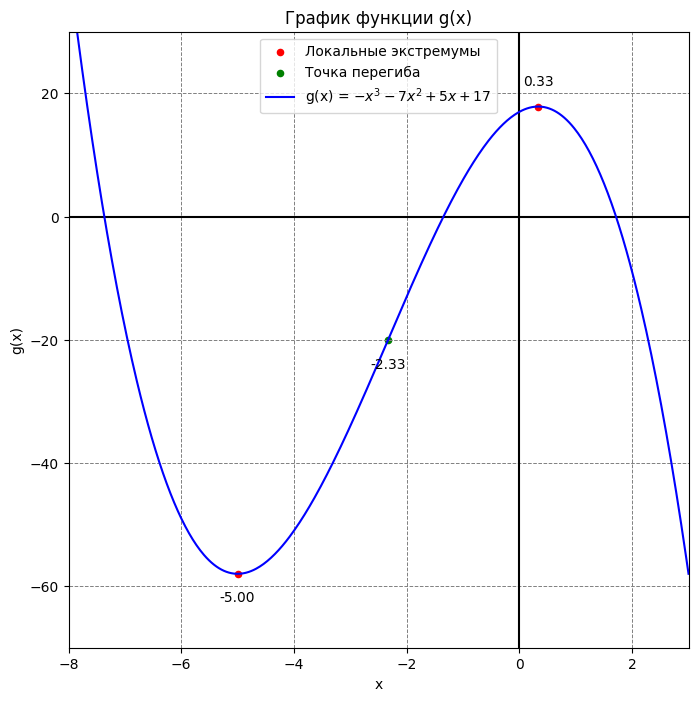

In [20]:
import numpy as np
import matplotlib.pyplot as plt

def g_np(x):
    return -x**3 - 7*x**2 + 5*x + 17

x_values = np.linspace(-8, 3, 500)
y_values = g_np(x_values)


x_min, y_min = -5, -58
x_max, y_max = 1/3, 482/27
x_inf, y_inf = -7/3, -542/27

plt.figure(figsize=(8, 8))

plt.axvline(x=0, c='black')
plt.axhline(y=0, c='black')
plt.grid(color='gray', linestyle='--', linewidth=0.7)

plt.xlim(-8, 3)
plt.ylim(-70, 30)

plt.xlabel('x')
plt.ylabel('g(x)')

plt.scatter([x_min, x_max], [y_min, y_max], label='Локальные экстремумы', color='red', s=20)
plt.annotate(f'{x_min:.2f}', (x_min, y_min), textcoords="offset points", xytext=(0, -20), ha='center')
plt.annotate(f'{x_max:.2f}', (x_max, y_max), textcoords="offset points", xytext=(0, 15), ha='center')

plt.scatter(x_inf, y_inf, label='Точка перегиба', color='green', s=20)
plt.annotate(f'{x_inf:.2f}', (x_inf, y_inf), textcoords="offset points", xytext=(0, -20), ha='center')

plt.title('График функции g(x)')
plt.plot(x_values, y_values, label='g(x) = $-x^3 - 7x^2 + 5x + 17$', color='blue')
plt.legend()
plt.show()

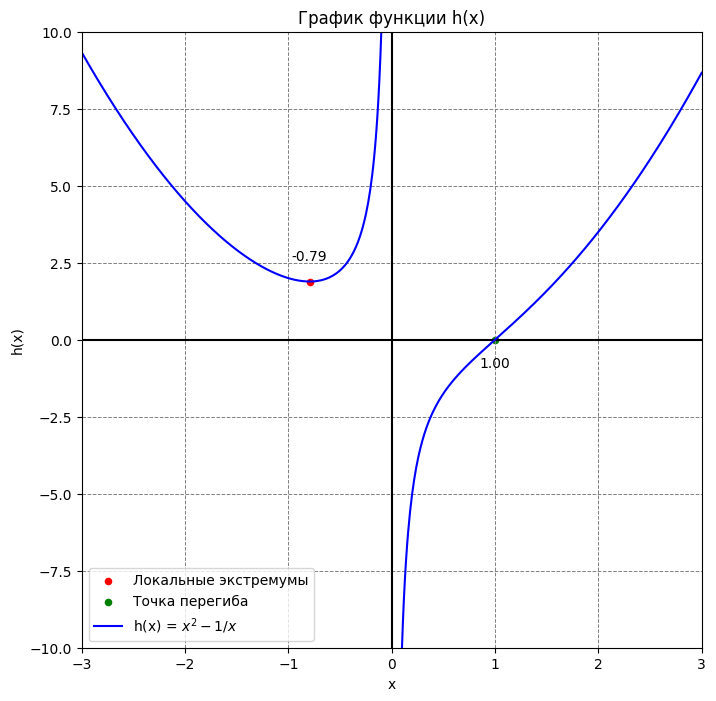

In [21]:
import numpy as np
import matplotlib.pyplot as plt

def h_np(x):
    return x**2 - 1/x

x_left = np.linspace(-3, -0.05, 300)
y_left = h_np(x_left)
x_right = np.linspace(0.05, 3, 300)
y_right = h_np(x_right)

x_min = -2**(2/3)/2
y_min = 3*2**(1/3)/2
x_inf, y_inf = 1, 0

plt.figure(figsize=(8, 8))

plt.axvline(x=0, c='black')
plt.axhline(y=0, c='black')
plt.grid(color='gray', linestyle='--', linewidth=0.7)

plt.xlim(-3, 3)
plt.ylim(-10, 10)

plt.xlabel('x')
plt.ylabel('h(x)')

plt.scatter(x_min, y_min, label='Локальные экстремумы', color='red', s=20)
plt.annotate(f'{x_min:.2f}', (x_min, y_min), textcoords="offset points", xytext=(0, 15), ha='center')

plt.scatter(x_inf, y_inf, label='Точка перегиба', color='green', s=20)
plt.annotate(f'{x_inf:.2f}', (x_inf, y_inf), textcoords="offset points", xytext=(0, -20), ha='center')

plt.title('График функции h(x)')
plt.plot(x_left, y_left, label='h(x) = $x^2 - 1/x$', color='blue')
plt.plot(x_right, y_right, color='blue')
plt.legend()
plt.show()

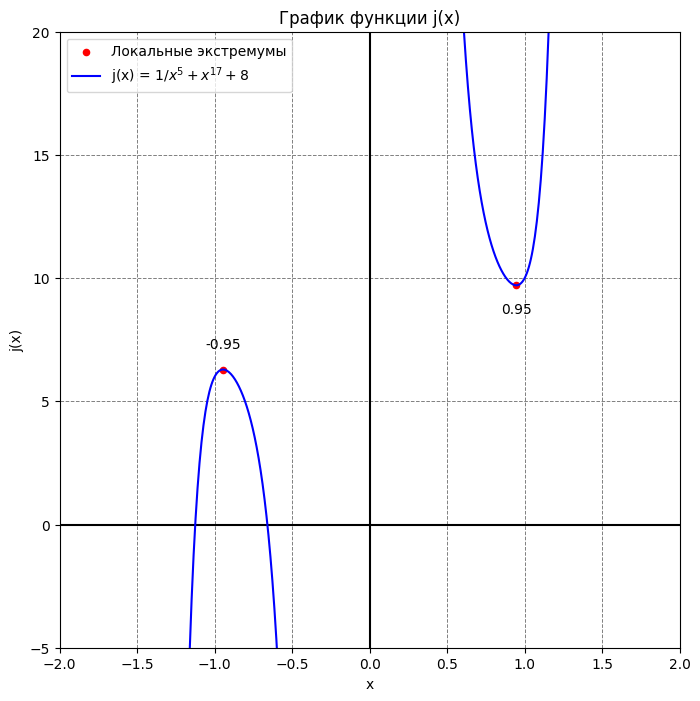

In [23]:
import numpy as np
import matplotlib.pyplot as plt

def j_np(x):
    return 1/x**5 + x**17 + 8

x_left = np.linspace(-2, -0.1, 300)
y_left = j_np(x_left)
x_right = np.linspace(0.1, 2, 300)
y_right = j_np(x_right)

x_max = -(5/17)**(1/22)
y_max = 1/x_max**5 + x_max**17 + 8

x_min = (5/17)**(1/22)
y_min = 1/x_min**5 + x_min**17 + 8

plt.figure(figsize=(8, 8))

plt.axvline(x=0, c='black')
plt.axhline(y=0, c='black')
plt.grid(color='gray', linestyle='--', linewidth=0.7)

plt.xlim(-2, 2)
plt.ylim(-5, 20)

plt.xlabel('x')
plt.ylabel('j(x)')

plt.scatter([x_max, x_min], [y_max, y_min], label='Локальные экстремумы', color='red', s=20)
plt.annotate(f'{x_max:.2f}', (x_max, y_max), textcoords="offset points", xytext=(0, 15), ha='center')
plt.annotate(f'{x_min:.2f}', (x_min, y_min), textcoords="offset points", xytext=(0, -20), ha='center')

plt.title('График функции j(x)')
plt.plot(x_left, y_left, label='j(x) = $1/x^5 + x^{17} + 8$', color='blue')
plt.plot(x_right, y_right, color='blue')
plt.legend()
plt.show()

### Задание 4 (0.75 балла).
Допишите функцию `gradient_descent`, которая ищет минимум функции одной переменной методом градиентного спуска:

* реализуйте шаг метода по формуле $x_{t+1} = x_t - \eta f'(x_t)$;
* добавьте **два условия останова**:
    1. производная почти равна нулю: $|f'(x_t)| < \delta$ (мы пришли в точку экстремума);
    2. точка почти перестала двигаться: $|x_{t+1} - x_t| < \varepsilon$;
* функция должна возвращать найденную точку и траекторию `trace` — список всех $x_t$ (она понадобится для графиков).

Функция принимает на вход sympy-выражение (как в задании 2). Чтобы не вызывать медленный `subs` на каждой итерации, производная заранее превращается в обычную python-функцию с помощью `sp.lambdify`.

In [24]:
import sympy as sp

x = sp.Symbol('x')

def gradient_descent(f_expr, x_start, learning_rate, epsilon, delta, num_iterations):
    df = sp.lambdify(x, sp.diff(f_expr, x))  # производная как обычная python-функция

    x_curr = x_start
    trace = [x_curr]

    for i in range(num_iterations):
        grad_value = df(x_curr)

        # TODO: условие останова (1) — если |grad_value| < delta, выходим из цикла
        if abs(grad_value) < delta:
            break
        
        # TODO: вычислите x_new по формуле градиентного спуска,
        # используя текущее значение (x_curr), размер шага (learning_rate) и производную (grad_value)
        # x_new = ...
        x_new = x_curr - learning_rate * grad_value
        trace.append(x_new)

        # TODO: условие останова (2) — если |x_new - x_curr| < epsilon, выходим из цикла
        if abs(x_new - x_curr) < epsilon:
            x_curr = x_new
            break
        
        x_curr = x_new

    return x_curr, trace

### Задание 5 (0.75 балла).

Подберите начальное приближение (сделайте несколько запусков из случайной начальной точки) и шаг градиентного спуска таким образом, чтобы процедура выдавала правильное значение наименьшего локального минимума функций (если он есть):
1. В качестве результата выведите на экран значение начального приближения ($x_0$), `learning_rate`
2. Нарисуйте график функции и изобразите на нём наименьший из найденных локальных минимумов; на оси $x$ подпишите значение этого минимума. \
(Постарайтесь сделать реализацию графика в виде функции, чтобы оптимизировать процесс. Потом функция понадобится вам в задании 6, но это не обязательное требование).
3. Если такой точки у функции нет (например, функция не ограничена снизу), поясните это текстом при помощи Markdown

**Обратите внимание:** функции $h(x)$ и $j(x)$ не определены в точке $x = 0$. Если шаг градиентного спуска «перепрыгнет» через ноль, метод окажется на другой ветви графика и может разойтись. Попробуйте стартовать с разных сторон от нуля и с разными `learning_rate` и опишите, что наблюдаете.

Пример графика:

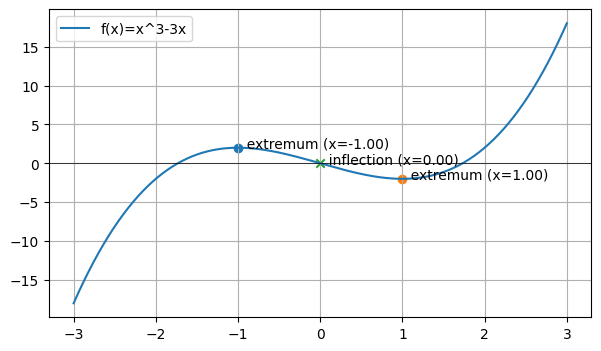

In [25]:
# Пример простого графика с отметками для функции f(x) = x^3 - 3x
# Attention! Вам в идеале нужно сделать это через функцию для оптимизации и последующего задания.
# Здесь используем свои имена (x_s, f_example), чтобы не перезаписать x и функции из заданий выше.

x_s = sp.symbols('x')
f_example = x_s**3 - 3*x_s
f1 = sp.diff(f_example, x_s)
f2 = sp.diff(f1, x_s)

crit = sp.solve(sp.Eq(f1, 0), x_s)   # экстремумы
infl = sp.solve(sp.Eq(f2, 0), x_s)   # кандидаты на перегиб

f_example_np = sp.lambdify(x_s, f_example, 'numpy')  # sympy-выражение -> numpy-функция

xx = np.linspace(-3, 3, 400)
yy = f_example_np(xx)
plt.figure(figsize=(7, 4))
plt.plot(xx, yy, label='f(x)=x^3-3x')

# отметки экстремумов
for c in crit:
    xc = float(c)
    plt.scatter([xc], [f_example_np(xc)], marker='o')
    plt.text(xc, f_example_np(xc), f'  extremum (x={xc:.2f})')

# отметка перегиба
for p in infl:
    xp = float(p)
    plt.scatter([xp], [f_example_np(xp)], marker='x')
    plt.text(xp, f_example_np(xp), f'  inflection (x={xp:.2f})')

plt.axhline(0, color='k', linewidth=0.5)
plt.legend()
plt.grid(True)
plt.show()

In [26]:
x_s = sp.Symbol('x')

def plot_trace(f_expr, x_found, trace=None, x_range=(-10, 10), title=''):

    f_np = sp.lambdify(x_s, f_expr, 'numpy')

    if x_range[0] < 0 < x_range[1]:
        x_left = np.linspace(x_range[0], -0.01, 300)
        x_right = np.linspace(0.01, x_range[1], 300)
        y_left = f_np(x_left)
        y_right = f_np(x_right)
    else:
        x_full = np.linspace(x_range[0], x_range[1], 500)
        y_full = f_np(x_full)

    plt.figure(figsize=(8, 6))
    plt.axhline(0, color='k', linewidth=0.5)
    plt.axvline(0, color='k', linewidth=0.5)
    plt.grid(True)

    if x_range[0] < 0 < x_range[1]:
        plt.plot(x_left, y_left, label=f'f(x)', color='blue')
        plt.plot(x_right, y_right, color='blue')
    else:
        plt.plot(x_full, y_full, label='f(x)', color='blue')

    y_found = float(f_np(x_found))
    plt.scatter([x_found], [y_found], color='red', s=50, zorder=5, label=f'Минимум x={x_found:.4f}')
    plt.text(x_found, y_found, f'  x={x_found:.2f}\n  f={y_found:.2f}', fontsize=9)

    if trace is not None:
        trace_y = [float(f_np(t)) for t in trace]
        plt.plot(trace, trace_y, 'o-', color='orange', markersize=4, label='Траектория градиента', alpha=0.7)

    plt.xlabel('x')
    plt.ylabel('f(x)')
    plt.title(title)
    plt.legend()
    plt.show()

Применение: выводим ($x_0$), `learning_rate` и график с помощью кода ниже

f(x): x_0 = 14.886791978505865, learning_rate = 0.1
 Локальный минимум: x = 14.999572312186963, f(x) = -223.99999981708314


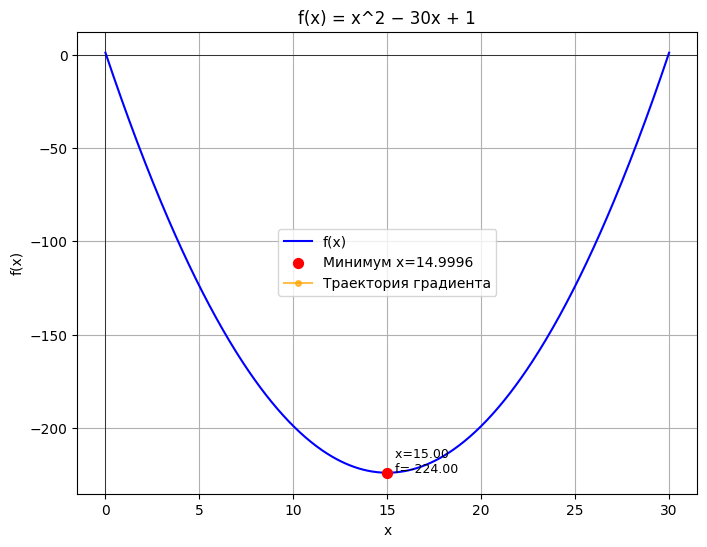

g(x): x_0 = -6.3592, learning_rate = 0.01
 Локальный минимум: x = -5.000060, f(x) = -58.0000


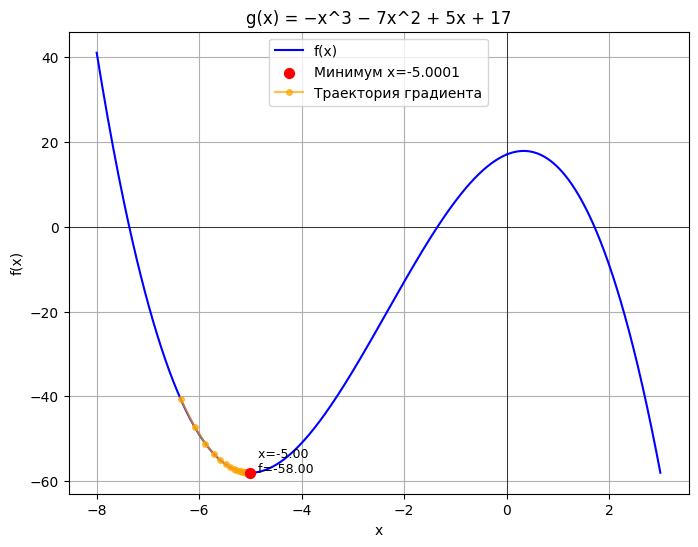

h(x): x_0 = -1.7537, learning_rate = 0.05
 Локальный минимум: x = -0.793864, f(x) = 1.8899


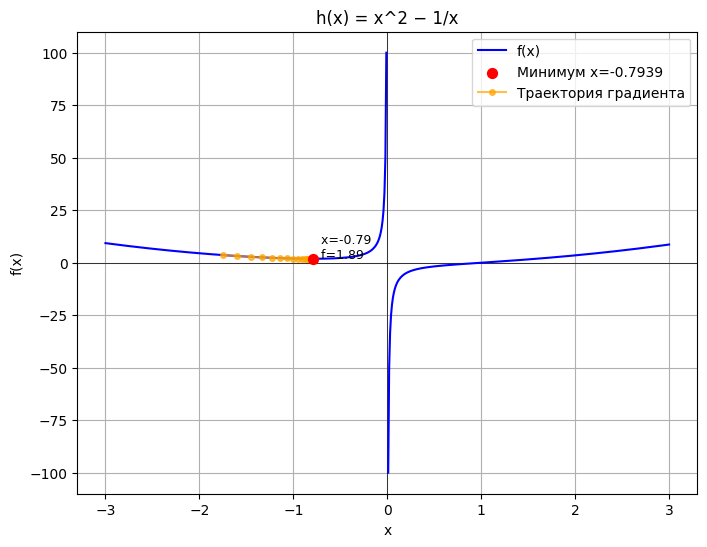

j(x): x_0 = 1.2168, learning_rate = 0.0001
 Локальный минимум: x = 0.945953, f(x) = 9.7091


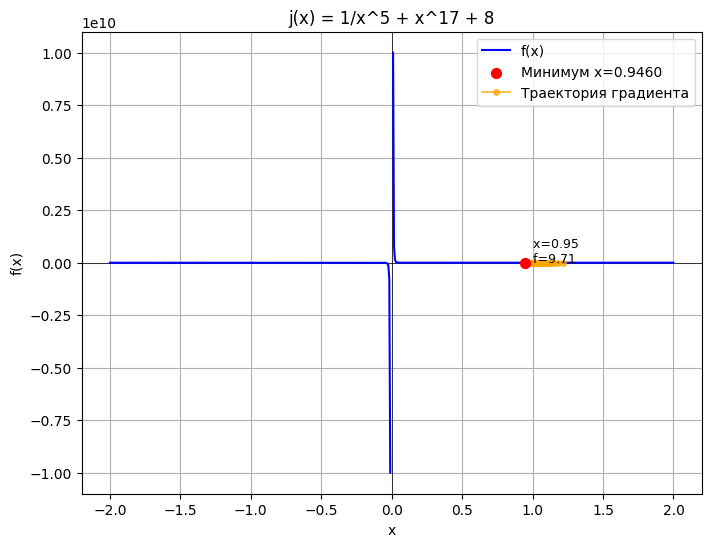

In [36]:
import random

# TODO: подберите начальную точку и шаг
# x_start = random.uniform(..., ...)
# learning_rate = ...
epsilon = 1e-6
delta = 1e-3
num_iterations = 1000

# TODO: для каждой функции из задания 1:
#   запускаем gradient_descent, вычисляем значение функции в найденной точке минимума,
#   выводим x_start и learning_rate, строим график с помощью plot_trace

f = x_s**2 - 30*x_s + 1

x_start = random.uniform(0, 25)
learning_rate = 0.1

x_found, trace = gradient_descent(f, x_start, learning_rate, epsilon, delta, num_iterations)
y_found = float(sp.lambdify(x_s, f)(x_found))

print(f"f(x): x_0 = {x_start}, learning_rate = {learning_rate}")
print(f" Локальный минимум: x = {x_found}, f(x) = {y_found}")

plot_trace(f, x_found, trace=trace, x_range=(0, 30), title='f(x) = x^2 − 30x + 1')


g = -x_s**3 - 7*x_s**2 + 5*x_s + 17

x_start = random.uniform(-8, -2)
learning_rate = 0.01

x_found, trace = gradient_descent(g, x_start, learning_rate, epsilon, delta, num_iterations)
y_found = float(sp.lambdify(x_s, g)(x_found))

print(f"g(x): x_0 = {x_start:.4f}, learning_rate = {learning_rate}")
print(f" Локальный минимум: x = {x_found:.6f}, f(x) = {y_found:.4f}")

plot_trace(g, x_found, trace=trace, x_range=(-8, 3), title='g(x) = −x^3 − 7x^2 + 5x + 17')


h = x_s**2 - 1/x_s

x_start = random.uniform(-3, -0.1)
learning_rate = 0.05

x_found, trace = gradient_descent(h, x_start, learning_rate, epsilon, delta, num_iterations)
y_found = float(sp.lambdify(x_s, h)(x_found))

print(f"h(x): x_0 = {x_start:.4f}, learning_rate = {learning_rate}")
print(f" Локальный минимум: x = {x_found:.6f}, f(x) = {y_found:.4f}")

plot_trace(h, x_found, trace=trace, x_range=(-3, 3), title='h(x) = x^2 − 1/x')


j = 1/x_s**5 + x_s**17 + 8

x_start = random.uniform(0.5, 1.5)
learning_rate = 0.0001

x_found, trace = gradient_descent(j, x_start, learning_rate, epsilon, delta, num_iterations)
y_found = float(sp.lambdify(x_s, j)(x_found))

print(f"j(x): x_0 = {x_start:.4f}, learning_rate = {learning_rate}")
print(f" Локальный минимум: x = {x_found:.6f}, f(x) = {y_found:.4f}")

plot_trace(j, x_found, trace=trace, x_range=(-2, 2), title='j(x) = 1/x^5 + x^17 + 8')

### Задание 5.1 (0.5 балла). Траектории градиентного спуска

Посмотрим своими глазами, как размер шага влияет на работу метода. Возьмите функцию $f(x) = x^2 - 30x + 1$ из задания 1 и одну и ту же начальную точку $x_0$. Подберите три значения `learning_rate`:

* **слишком маленький** — за разумное число итераций метод так и не дошёл до минимума;
* **нормальный** — метод быстро и спокойно сходится;
* **слишком большой** — метод «прыгает» через минимум всё дальше и расходится.

Для каждого значения запустите `gradient_descent` из задания 4 и постройте два графика рядом:

1. график функции $f(x)$, на котором точками, соединёнными линией, показана траектория `trace` (для каждого `learning_rate` — свой цвет);
2. значение $x_t$ в зависимости от номера итерации $t$ (горизонтальной линией отметьте настоящий минимум).

*Подсказки:* при слишком большом шаге значения быстро улетают в бесконечность, поэтому для этого запуска ограничьте число итераций (например, 10–20) и задайте пределы осей через `plt.xlim` / `plt.ylim`. Если найдёте «промежуточный» шаг, при котором метод сходится, но с колебаниями вокруг минимума, — покажите и его.

Графики пригодятся для ответа на вопрос ниже.

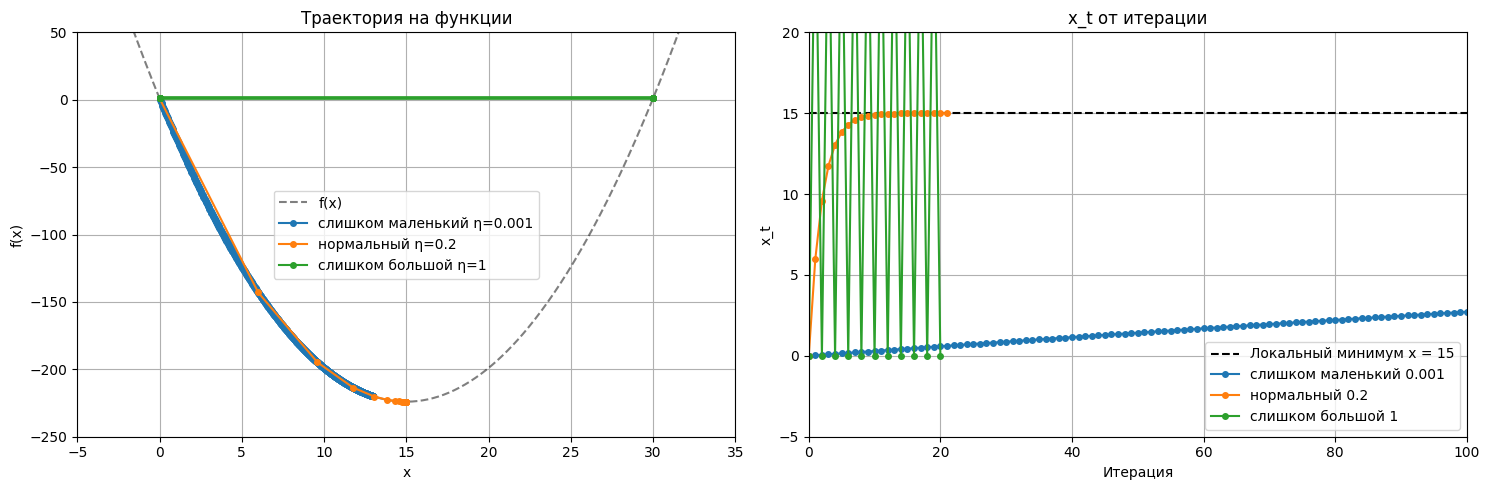

In [40]:
# TODO: подберите три значения learning rate
learning_rates = {
    'слишком маленький': 0.001,
    'нормальный': 0.2,
    'слишком большой': 1,
}
x_start = 0

f_expr = x**2 - 30*x + 1
f_np = sp.lambdify(x, f_expr, 'numpy')
epsilon = 1e-6
delta = 1e-3

fig, axs = plt.subplots(1, 2, figsize=(15, 5))
x_range = np.linspace(-5, 35, 500)
axs[0].plot(x_range, f_np(x_range), 'k--', alpha=0.5, label='f(x)')

axs[1].axhline(y=15, color='black', linestyle='--', label='Локальный минимум x = 15')

for name, lr in learning_rates.items():
    if name == 'слишком большой':
        num_iter = 20
    else:
        num_iter = 1000
    
    x_found, trace = gradient_descent(f_expr, x_start, lr, epsilon, delta, num_iter)
    
    trace_y = [f_np(t) for t in trace]
    axs[0].plot(trace, trace_y, 'o-', label=f'{name} η={lr}', markersize=4)

    axs[1].plot(range(len(trace)), trace, 'o-', label=f'{name} {lr}', markersize=4)

# TODO: график самой функции на axs[0], линия настоящего минимума на axs[1],
#       подписи осей, заголовки, легенды, пределы осей
axs[0].set_xlabel('x')
axs[0].set_ylabel('f(x)')
axs[0].set_title('Траектория на функции')
axs[0].legend()
axs[0].grid(True)
axs[0].set_xlim(-5, 35)
axs[0].set_ylim(-250, 50)

axs[1].set_xlabel('Итерация')
axs[1].set_ylabel('x_t')
axs[1].set_title('x_t от итерации')
axs[1].legend()
axs[1].grid(True)
axs[1].set_xlim(0, 100)
axs[1].set_ylim(-5, 20)

plt.tight_layout()
plt.show()

### **Вопрос:**

Почему слишком большой learning rate может приводить к расходимости алгоритма, а слишком маленький — к медленной сходимости? Опишите кратко, опираясь на графики из задания 5.1.

**Ваш ответ:**
Слишком большой learning rate уходит в бесконечность, потому что шаг слишком велик и мы перелетаем через локальный минимум функции.
Слишком маленький очень долго будет смешяться к минимуму, поэтому потребуется тысячи итераций.
```
```
**Ответ нейросети:**
Слишком большой learning rate (коэффициент обучения) заставляет веса модели делать чрезмерно резкие шаги, а слишком маленький — застревать в микроскопических перемещениях

### Задание 6 $-$ бонус (0.5 балла).

* Реализуйте [метод Ньютона](https://en.wikipedia.org/wiki/Newton%27s_method_in_optimization) (метод второго порядка) для поиска минимума функции. Про метод ещё можно почитать [здесь](https://math.semestr.ru/optim/minimum.php).
* Примените метод Ньютона для поиска минимума указанных функций (в ответе выведите подходящее значение начальной точки, график с найденным и подписанным значением минимума, как в задании 5).

In [42]:
import sympy as sp

x = sp.Symbol('x')

def newton_method(f_expr, x_start, epsilon=1e-6, delta=1e-6, max_iter=100):
    f_prime = sp.diff(f_expr, x)
    f_double_prime = sp.diff(f_prime, x)
    df = sp.lambdify(x, f_prime, 'numpy')
    d2f = sp.lambdify(x, f_double_prime, 'numpy')
    
    x_curr = float(x_start)
    trace = [x_curr] 
    
    for i in range(max_iter):
        grad = df(x_curr)
        hess = d2f(x_curr)
        
        if abs(grad) < delta:
            break
            
        if abs(hess) < 1e-10:
            break
            
        x_new = x_curr - grad / hess
        trace.append(x_new)
        
        if abs(x_new - x_curr) < epsilon:
            x_curr = x_new
            break
            
        x_curr = x_new
        
    f_val = float(f_expr.subs(x, x_curr))
    
    return x_curr, f_val, len(trace) - 1

f1 = x**2 - 30*x + 1
x_res1, y_res1, iters1 = newton_method(f1, x_start=0.0)
print(f"f(x): старт = 0.0")
print(f"Локальный минимум: x = {x_res1}, f(x) = {y_res1}")
print(f"Количество итераций: {iters1}\n")

f2 = -x**3 - 7*x**2 + 5*x + 17
x_res2, y_res2, iters2 = newton_method(f2, x_start=-6.0)
print(f"g(x): старт = -6.0")
print(f"Локальный минимум: x = {x_res2}, f(x) = {y_res2}")
print(f"Количество итераций: {iters2}\n")

f3 = x**2 - 1/x
x_res3, y_res3, iters3 = newton_method(f3, x_start=-1.0)
print(f"h(x): старт = -1.0")
print(f"Локальный минимум: x = {x_res3}, f(x) = {y_res3}")
print(f"Количество итераций: {iters3}\n")

f4 = 1/x**5 + x**17 + 8
x_res4, y_res4, iters4 = newton_method(f4, x_start=1.0)
print(f"j(x): старт = 1.0")
print(f"Локальный минимум: x = {x_res4}, f(x) = {y_res4}")
print(f"Количество итераций: {iters4}\n")

f(x): старт = 0.0
Локальный минимум: x = 15.0, f(x) = -224.0
Количество итераций: 1

g(x): старт = -6.0
Локальный минимум: x = -5.000000000000796, f(x) = -58.0
Количество итераций: 4

h(x): старт = -1.0
Локальный минимум: x = -0.7937005259066797, f(x) = 1.8898815748423097
Количество итераций: 4

j(x): старт = 1.0
Локальный минимум: x = 0.9458926862391149, f(x) = 9.709087990271515
Количество итераций: 4



### Бонус к заданию 6 (0.25 балла).
Сравните скорость работы градиентного спуска и метода Ньютона при одинаковой точности решения $|x_{found}-x_{true}|<10^{-5}$:
* за сколько итераций каждый метод сходится (в среднем по всем функциям для правильно подобранных значений гиперпараметров)? Какой быстрее?
* какой метод дает более точный результат при фиксированном числе итераций $N=10$? (для ответа на этот вопрос добавьте в процедуру градиентного спуска возможность останавливаться при достижении некоторого количества итераций $N$)

In [43]:
import sympy as sp
import numpy as np

x = sp.Symbol('x')

# --- Методы из прошлых заданий ---

def gradient_descent(f_expr, x_start, learning_rate, epsilon, delta, num_iterations):
    df = sp.lambdify(x, sp.diff(f_expr, x))
    x_curr = x_start
    trace = [x_curr]

    for i in range(num_iterations):
        grad_value = df(x_curr)

        if abs(grad_value) < delta:
            break
        
        x_new = x_curr - learning_rate * grad_value
        trace.append(x_new)

        if abs(x_new - x_curr) < epsilon:
            x_curr = x_new
            break
        
        x_curr = x_new

    return x_curr, trace


def newton_method(f_expr, x_start, epsilon=1e-6, delta=1e-6, max_iter=100):
    f_prime = sp.diff(f_expr, x)
    f_double_prime = sp.diff(f_prime, x)
    df = sp.lambdify(x, f_prime, 'numpy')
    d2f = sp.lambdify(x, f_double_prime, 'numpy')
    
    x_curr = float(x_start)
    trace = [x_curr] 
    
    for i in range(max_iter):
        grad = df(x_curr)
        hess = d2f(x_curr)
        
        if abs(grad) < delta:
            break
            
        if abs(hess) < 1e-10:
            break
            
        x_new = x_curr - grad / hess
        trace.append(x_new)
        
        if abs(x_new - x_curr) < epsilon:
            x_curr = x_new
            break
            
        x_curr = x_new
        
    f_val = float(f_expr.subs(x, x_curr))
    
    return x_curr, f_val, len(trace) - 1


tests = [
    ("f(x)", x**2 - 30*x + 1, 0.0, 0.3, 15.0),
    ("g(x)", -x**3 - 7*x**2 + 5*x + 17, -6.0, 0.01, -5.0),
    ("h(x)", x**2 - 1/x, -1.0, 0.05, float(-2**(2/3)/2)),
    ("j(x)", 1/x**5 + x**17 + 8, 1.0, 0.001, float((5/17)**(1/22)))
]


print("Точность |x - x_true| < 10^-5\n")

gd_iters_list = []
newton_iters_list = []

for name, f_expr, start, lr, x_true in tests:
    x_gd, trace_gd = gradient_descent(f_expr, start, lr, 1e-6, 1e-6, 10000)
    gd_iters = len(trace_gd) - 1
    
    x_new, _, newton_iters = newton_method(f_expr, start, 1e-6, 1e-6, 100)
    
    gd_iters_list.append(gd_iters)
    newton_iters_list.append(newton_iters)
    
    print(f"{name}: градиентный спуск = {gd_iters} итер., метод Ньютона = {newton_iters} итер.")

print(f"\nСреднее: градиентный спуск = {np.mean(gd_iters_list):.1f}, метод Ньютона = {np.mean(newton_iters_list):.1f}")
print(f"Метод Ньютона быстрее в {np.mean(gd_iters_list)/np.mean(newton_iters_list):.1f} раз\n")


print("Точность при N=10 итерациях\n")

def gradient_descent_n(f_expr, x_start, learning_rate, n):
    """Градиентный спуск с фиксированным числом итераций N"""
    df = sp.lambdify(x, sp.diff(f_expr, x))
    x_curr = x_start
    for _ in range(n):
        x_curr = x_curr - learning_rate * df(x_curr)
    return x_curr

gd_errors = []
newton_errors = []

for name, f_expr, start, lr, x_true in tests:
    x_gd = gradient_descent_n(f_expr, start, lr, 10)
    gd_err = abs(x_gd - x_true)
    
    x_new, _, _ = newton_method(f_expr, start, 1e-15, 1e-15, 10)
    newton_err = abs(x_new - x_true)
    
    gd_errors.append(gd_err)
    newton_errors.append(newton_err)
    
    print(f"{name}: градиентный спуск ошибка = {gd_err:.2e}, метод Ньютона ошибка = {newton_err:.2e}")

print(f"\nСредняя ошибка: градиентный спуск = {np.mean(gd_errors):.2e}, метод Ньютона = {np.mean(newton_errors):.2e}")

Часть 1: Точность |x - x_true| < 10^-5

f(x): градиентный спуск = 19 итер., метод Ньютона = 1 итер.
g(x): градиентный спуск = 69 итер., метод Ньютона = 4 итер.
h(x): градиентный спуск = 33 итер., метод Ньютона = 4 итер.
j(x): градиентный спуск = 51 итер., метод Ньютона = 4 итер.

Среднее: градиентный спуск = 43.0, метод Ньютона = 3.2
Метод Ньютона быстрее в 13.2 раз

Точность при N=10 итерациях

f(x): градиентный спуск ошибка = 1.57e-03, метод Ньютона ошибка = 0.00e+00
g(x): градиентный спуск ошибка = 1.47e-01, метод Ньютона ошибка = 0.00e+00
h(x): градиентный спуск ошибка = 8.11e-03, метод Ньютона ошибка = 1.11e-16
j(x): градиентный спуск ошибка = 6.93e-03, метод Ньютона ошибка = 0.00e+00

Средняя ошибка: градиентный спуск = 4.10e-02, метод Ньютона = 2.78e-17


## Практика: часть 2 (2.5 балла + бонус)

**Напоминание:**
* MSE в матричном виде: $Q(w) = \dfrac{1}{\ell} \left( y - Xw \right)^T \left( y - Xw \right)$ ($\ell$ - кол-во объектов)
* Тогда его градиент будет: $\triangledown_wQ = \dfrac{-2}{\ell}X^T\big(y - Xw\big)$

### **Вопрос:**
Выведите эту формулу для градиента MSE.

**Ваш ответ:**

**Ответ нейросети:**
### Вывод формулы градиента функции потерь MSE в матричном виде

**Исходный функционал:**
$$Q(w) = \frac{1}{\ell} (y - Xw)^T (y - Xw)$$

Где:
* $X \in \mathbb{R}^{\ell \times d}$ — матрица «объект-признак» ($\ell$ — число объектов, $d$ — число признаков).
* $y \in \mathbb{R}^{\ell}$ — вектор истинных ответов.
* $w \in \mathbb{R}^{d}$ — вектор весов модели.

#### Пошаговый алгебраический вывод:

1. **Раскроем скобки.** По свойству транспонирования $(AB)^T = B^T A^T$:
   $$Q(w) = \frac{1}{\ell} (y^T - w^T X^T)(y - Xw) = \frac{1}{\ell} \Big( y^T y - y^T X w - w^T X^T y + w^T X^T X w \Big)$$

2. **Упростим слагаемые.** Заметим, что выражение $y^T X w$ является скаляром (матрицей $1 \times 1$). Скаляр равен своему транспонированию: $(y^T X w)^T = w^T X^T y$. Следовательно, два средних слагаемых равны. Объединим их:
   $$Q(w) = \frac{1}{\ell} \Big( y^T y - 2 w^T X^T y + w^T X^T X w \Big)$$

3. **Возьмем градиент по вектору $w$**, используя правила матричного дифференцирования:
   * Градиент константы: $\nabla_w (y^T y) = 0$
   * Градиент линейной формы: $\nabla_w (w^T a) = a \implies \nabla_w (-2 w^T X^T y) = -2 X^T y$
   * Градиент квадратичной формы: $\nabla_w (w^T A w) = 2 A w$ (для симметричной матрицы $A = X^T X$) $\implies \nabla_w (w^T X^T X w) = 2 X^T X w$

4. **Собираем все вместе:**
   $$\nabla_w Q = \frac{1}{\ell} \Big( 0 - 2 X^T y + 2 X^T X w \Big) = \frac{2}{\ell} \Big( X^T X w - X^T y \Big)$$

5. **Выносим общий множитель $-2 X^T$ за скобки:**
   $$\nabla_w Q = \frac{-2}{\ell} X^T (y - Xw)$$
   *Формула успешно выведена!*


### Задание 7 (1 балл).
Реализуйте линейную регрессию с функцией потерь MSE, обучаемую с помощью:

* Градиентного спуска (0.3 балла);

* Стохастического градиентного спуска (0.3 балла);

* Метода Momentum (0.4 балла)


Во всех пунктах необходимо соблюдать следующие условия:

* Все вычисления должны быть векторизованы;
* Циклы средствами python допускается использовать только для итераций градиентного спуска;
* В качестве критерия останова необходимо использовать (одновременно):

    * проверку на евклидову норму разности весов на двух соседних итерациях (например, меньше некоторого малого числа порядка $10^{-6}$, задаваемого параметром `tolerance`);
    * достижение максимального числа итераций (например, 10000, задаваемого параметром `max_iter`).
* Чтобы проследить, что оптимизационный процесс действительно сходится, будем использовать атрибут класса `loss_history` — в нём после вызова метода `fit` должны содержаться значения функции потерь (MSE на **всей** обучающей выборке) для всех итераций, начиная с первой (до совершения первого шага по антиградиенту);
* Инициализировать веса можно случайным образом или нулевым вектором.
* Свободный член отдельно не заводим: в задании 8 мы добавим к матрице признаков столбец из единиц, и вес при нём как раз и будет свободным членом.

Ниже приведены шаблоны классов. `GradientDescent` — базовый класс, `SGD` и `Momentum` наследуют его и переопределяют нужные методы.

**Что нужно реализовать:**

Класс `GradientDescent` (базовый, полный градиентный спуск):
- `calc_loss(X, y)` — MSE при текущих весах;
- `calc_gradient(X, y)` — градиент MSE по весам (формула выше);
- `fit(X, y)` — обучение на всём наборе данных;
- `predict(X)` — прогноз.

Класс `SGD` — наследует `GradientDescent`:
- добавляется аргумент `batch_size`;
- в `fit` на каждой итерации градиент считается не по всей выборке, а по случайному мини-батчу из `batch_size` объектов.

Класс `Momentum` — наследует `SGD`:
- добавляется аргумент `beta` (коэффициент импульса);
- в `fit` используется «скорость» $v$ — накопленное среднее градиентов:
  $$
  v_t = \beta v_{t-1} + (1 - \beta) \nabla L, \quad
  w_{t+1} = w_t - \eta v_t
  $$
- если передать `batch_size`, равный размеру выборки, получится полный градиентный спуск с импульсом.

> В PyTorch (и в следующем ДЗ) momentum записывается чуть иначе: $v_t = \beta v_{t-1} + \nabla L$, без множителя $(1-\beta)$. Это та же идея, отличается только масштаб шага.

In [48]:
import numpy as np


class GradientDescent:
    """
    Линейная регрессия с MSE, обучаемая полным градиентным спуском.

    eta       : float — скорость обучения (learning rate)
    max_iter  : int — максимальное число итераций
    tolerance : float — порог останова по норме разности весов на соседних итерациях
    w0        : np.ndarray или None — начальные веса (если None — нулевой вектор)
    """
    def __init__(self, eta=1e-2, max_iter=10000, tolerance=1e-6, w0=None):
        self.eta = eta
        self.max_iter = max_iter
        self.tolerance = tolerance
        self.w0 = w0
        self.w = None
        self.loss_history = []

    def calc_loss(self, X, y):
        """
        X: np.ndarray формы (ell, d), y: np.ndarray формы (ell,)
        Возвращает: float — MSE при текущих весах self.w
        """
        err = y - X @ self.w
        return np.mean(err ** 2)

    def calc_gradient(self, X, y):
        """
        X: np.ndarray формы (ell, d) (ell может быть равен размеру батча), y: np.ndarray формы (ell,)
        Возвращает: np.ndarray формы (d,) — градиент MSE по весам
        """
        ell = X.shape[0]
        err = y - X @ self.w
        return (-2 / ell) * (X.T @ err)

    def fit(self, X, y):
        """
        X: np.ndarray формы (ell, d), y: np.ndarray формы (ell,)
        Не забудьте:
          - инициализировать self.w (из w0 или нулями) и очистить self.loss_history;
          - на каждой итерации сначала сохранить loss, затем сделать шаг;
          - остановиться, если ||w_new - w_old|| < tolerance или достигнут max_iter.
        Возвращает: self
        """
        
        if self.w0 is not None:
            self.w = self.w0.copy()
        else:
            self.w = np.zeros(X.shape[1])
            
        self.loss_history = []

        for i in range(self.max_iter):
            loss = self.calc_loss(X, y)
            self.loss_history.append(loss)

            grad = self.calc_gradient(X, y)
            w_new = self.w - self.eta * grad

            if np.linalg.norm(w_new - self.w) < self.tolerance:
                self.w = w_new
                break
                
            self.w = w_new

        return self

    def predict(self, X):
        if self.w is None:
            raise Exception('Not trained yet')
        return X @ self.w


class SGD(GradientDescent):
    """
    Стохастический градиентный спуск: градиент считается по случайному мини-батчу.
    batch_size : int — размер мини-батча
    """
    def __init__(self, eta=1e-2, max_iter=10000, tolerance=1e-6, w0=None, batch_size=1):
        super().__init__(eta, max_iter, tolerance, w0)
        self.batch_size = batch_size

    def fit(self, X, y):
        # TODO: как в GradientDescent.fit, но на каждой итерации:
        #   - выберите случайные индексы мини-батча (np.random.choice)
        #   - посчитайте градиент только по батчу
        #   - loss в loss_history считайте по всей выборке
        if self.w0 is not None:
            self.w = self.w0.copy()
        else:
            self.w = np.zeros(X.shape[1])
        
        self.loss_history = []
        n_samples = X.shape[0]

        for i in range(self.max_iter):
            loss = self.calc_loss(X, y)
            self.loss_history.append(loss)

            indices = np.random.choice(n_samples, self.batch_size, replace=False)
            X_batch = X[indices]
            y_batch = y[indices]

            grad = self.calc_gradient(X_batch, y_batch)
            w_new = self.w - self.eta * grad

            if np.linalg.norm(w_new - self.w) < self.tolerance:
                self.w = w_new
                break
                
            self.w = w_new
          
        return self


class Momentum(SGD):
    """
    SGD с импульсом.
    beta : float — коэффициент импульса
    """
    def __init__(self, eta=1e-2, max_iter=10000, tolerance=1e-6, w0=None, batch_size=1, beta=0.9):
        super().__init__(eta, max_iter, tolerance, w0, batch_size)
        self.beta = beta

    def fit(self, X, y):
        # TODO: как в SGD.fit, но шаг делается по «скорости» v (см. формулу выше)
        if self.w0 is not None:
            self.w = self.w0.copy()
        else:
            self.w = np.zeros(X.shape[1])
            
        self.loss_history = []
        n_samples = X.shape[0]
        
        v = np.zeros_like(self.w)

        for i in range(self.max_iter):
            loss = self.calc_loss(X, y)
            self.loss_history.append(loss)

            indices = np.random.choice(n_samples, self.batch_size, replace=False)
            X_batch = X[indices]
            y_batch = y[indices]

            grad = self.calc_gradient(X_batch, y_batch)

            v = self.beta * v + (1 - self.beta) * grad
            w_new = self.w - self.eta * v

            if np.linalg.norm(w_new - self.w) < self.tolerance:
                self.w = w_new
                break
                
            self.w = w_new

        return self

### **Задание 8 (0 баллов)**.
* Загрузите данные [NYC Taxi Trip Duration](https://www.kaggle.com/c/nyc-taxi-trip-duration/data) — файл `train.csv` (для скачивания нужен аккаунт Kaggle и принятие правил соревнования);
* Удалите столбцы `id` и `dropoff_datetime` — время окончания поездки «подсказывает» ответ (это утечка целевой переменной);
* Из `pickup_datetime` получите час и день недели поездки, `store_and_fwd_flag` переведите в 0/1. В итоге в матрице признаков должны остаться только числа. По желанию добавьте расстояние между точками посадки и высадки — это заметно улучшит качество;
* Разбейте выборку на обучающую и тестовую в отношении 7:3 с `random_state=0`;
* Отмасштабируйте признаки с помощью `StandardScaler` (обучайте его только на train!) — без этого градиентный спуск будет сходиться очень плохо;
* Добавьте к матрицам признаков столбец из единиц (свободный член);
* Преобразуйте целевую переменную `trip_duration` как $\hat{y} = \log{(y + 1)}$.

In [58]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

train = pd.read_csv('train.csv')

train = train.drop(columns=['id', 'dropoff_datetime'])

train['pickup_datetime'] = pd.to_datetime(train['pickup_datetime'])
train['hour'] = train['pickup_datetime'].dt.hour
train['day_of_week'] = train['pickup_datetime'].dt.dayofweek
train = train.drop(columns=['pickup_datetime'])

train['store_and_fwd_flag'] = train['store_and_fwd_flag'].map({'Y': 1, 'N': 0})

X = train.drop(columns=['trip_duration'])
y = train['trip_duration']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = np.hstack([np.ones((X_train_scaled.shape[0], 1)), X_train_scaled])
X_test_scaled = np.hstack([np.ones((X_test_scaled.shape[0], 1)), X_test_scaled])

y_train_log = np.log1p(y_train).values
y_test_log = np.log1p(y_test).values

### Вопрос:
Что такое $R^2$?

**Ответ нейросети:**
Коэффициент детерминации (R² или R-квадрат) — это статистический показатель, который показывает, какая доля дисперсии (разброса) зависимой переменной объясняется построенной моделью зависимости. 
**Ваш ответ:**
Коэффицент, определяющий зависимость переменной от данных.

### Задание 9 (1 балл).

Обучите и провалидируйте модели на данных из предыдущего пункта, сравните качество между методами по метрикам MSE и $R^2$. Исследуйте влияние параметров `max_iter` и `eta` (для SGD — ещё `batch_size`, для Momentum — ещё `beta`) на процесс оптимизации. Согласуется ли оно с вашими ожиданиями?

*Подсказка*:

Подбирайте `eta` **по логарифмической шкале** — это помогает быстрее найти разумный диапазон значений.  
Можно использовать `numpy.logspace` для создания набора значений от, например, `1e-4` до `1`:

In [54]:
# Пример: 5 значений eta от 1e-4 до 1 в логарифмической шкале
etas = np.logspace(-4, 0, 5)
print(etas)
# должно получиться [0.0001 0.001 0.01 0.1 1.0]
def calc_r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)
def calc_mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

[1.e-04 1.e-03 1.e-02 1.e-01 1.e+00]


In [59]:
gd = GradientDescent(eta=0.01, max_iter=1000, tolerance=1e-6)
gd.fit(X_train_scaled, y_train_log)
y_pred_gd = gd.predict(X_test_scaled)
mse_test = calc_mse(y_test_log, y_pred_gd)
r2_test = calc_r2(y_test_log, y_pred_gd)
print(f"Градиентный спуск")
print(f"MSE = {mse_test}")
print(f"R2 = {r2_test}")
print(f"Количество итераций = {len(gd.loss_history)}")

sgd = SGD(eta=0.01, max_iter=1000, tolerance=1e-6, batch_size=32)
sgd.fit(X_train_scaled, y_train_log)
y_pred_sgd = sgd.predict(X_test_scaled)
mse_test = calc_mse(y_test_log, y_pred_sgd)
r2_test = calc_r2(y_test_log, y_pred_sgd)
print(f"\nSGD (batch_size=32)")
print(f"MSE = {mse_test}")
print(f"R2 = {r2_test}")
print(f"Количество итераций = {len(sgd.loss_history)}")

momentum = Momentum(eta=0.01, max_iter=1000, tolerance=1e-6, batch_size=32, beta=0.9)
momentum.fit(X_train_scaled, y_train_log)
y_pred_mom = momentum.predict(X_test_scaled)
mse_test = calc_mse(y_test_log, y_pred_mom)
r2_test = calc_r2(y_test_log, y_pred_mom)
print(f"\nMomentum (batch_size=32, beta=0.9)")
print(f"MSE = {mse_test}")
print(f"R2 = {r2_test}")
print(f"Количество итераций = {len(momentum.loss_history)}")

Градиентный спуск
MSE = 0.6003816311218825
R2 = 0.046480884621637464
Количество итераций = 1000

SGD (batch_size=32)
MSE = 0.5878789048447958
R2 = 0.06633756890637921
Количество итераций = 1000

Momentum (batch_size=32, beta=0.9)
MSE = 0.5905587727256071
R2 = 0.06208143394391019
Количество итераций = 1000


In [61]:

print("Влияенеие max_iter на Градиента")
for max_iter in [10, 50, 100, 500, 1000]:
    model = GradientDescent(eta=0.01, max_iter=max_iter, tolerance=1e-6)
    model.fit(X_train_scaled, y_train_log)
    y_pred = model.predict(X_test_scaled)
    mse = calc_mse(y_test_log, y_pred)
    r2 = calc_r2(y_test_log, y_pred)
    print(f"max_iter={max_iter}: MSE={mse}, R2={r2}, итераций={len(model.loss_history)}")

print("Влияние eta для градиента")
etas = np.logspace(-4, 0, 5)
for eta in etas:
    model = GradientDescent(eta=eta, max_iter=500, tolerance=1e-6)
    model.fit(X_train_scaled, y_train_log)
    y_pred = model.predict(X_test_scaled)
    mse = calc_mse(y_test_log, y_pred)
    r2 = calc_r2(y_test_log, y_pred)
    print(f"eta={eta}: MSE={mse}, R2={r2}, итераций={len(model.loss_history)}")

print("Влияние batch_size для SGD")
for batch_size in [1, 16, 64, 256]:
    model = SGD(eta=0.01, max_iter=500, tolerance=1e-6, batch_size=batch_size)
    model.fit(X_train_scaled, y_train_log)
    y_pred = model.predict(X_test_scaled)
    mse = calc_mse(y_test_log, y_pred)
    r2 = calc_r2(y_test_log, y_pred)
    print(f"batch_size={batch_size}: MSE={mse}, R2={r2}, итераций={len(model.loss_history)}")

print("Влияние beta для Momentum-")
for beta in [0.0, 0.5, 0.9, 0.99]:
    model = Momentum(eta=0.01, max_iter=500, tolerance=1e-6, batch_size=32, beta=beta)
    model.fit(X_train_scaled, y_train_log)
    y_pred = model.predict(X_test_scaled)
    mse = calc_mse(y_test_log, y_pred)
    r2 = calc_r2(y_test_log, y_pred)
    print(f"beta={beta}: MSE={mse}, R2={r2}, итераций={len(model.loss_history)}")

Влияенеие max_iter на Градиента
max_iter=10: MSE=28.542142642066327, R2=-44.330298583937115, итераций=10
max_iter=50: MSE=6.152058667466853, R2=-8.770627937762328, итераций=50
max_iter=100: MSE=1.3374365388439722, R2=-1.1241011371553982, итераций=100
max_iter=500: MSE=0.6004481322959869, R2=0.04637526823130045, итераций=500
max_iter=1000: MSE=0.6003816311218825, R2=0.046480884621637464, итераций=1000
Влияние eta для градиента
eta=0.0001: MSE=34.86652654448733, R2=-54.3746114532051, итераций=500
eta=0.001: MSE=6.25440462002103, R2=-8.93317258783708, итераций=500
eta=0.01: MSE=0.6004481322959869, R2=0.04637526823130045, итераций=500
eta=0.1: MSE=0.6003689200001474, R2=0.04650107227716194, итераций=234


C:\Users\aminov_aa\AppData\Local\Programs\Python\Python311\.venv\Lib\site-packages\numpy\_core\_methods.py:135: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\TMP\ipykernel_24096\1302942119.py:27: RuntimeWarning: overflow encountered in square
  return np.mean(err ** 2)
C:\TMP\ipykernel_24096\1778927189.py:10: RuntimeWarning: overflow encountered in square
  return np.mean((y_true - y_pred) ** 2)
C:\TMP\ipykernel_24096\1778927189.py:6: RuntimeWarning: overflow encountered in square
  ss_res = np.sum((y_true - y_pred) ** 2)


eta=1.0: MSE=inf, R2=-inf, итераций=500
Влияние batch_size для SGD
batch_size=1: MSE=51.832208467317116, R2=-81.31930992543943, итераций=500
batch_size=16: MSE=0.5952307482500185, R2=0.05466145681905732, итераций=500
batch_size=64: MSE=0.5890689549444906, R2=0.0644475451956329, итераций=500
batch_size=256: MSE=0.813400080468011, R2=-0.29183253612750026, итераций=500
Влияние beta для Momentum-
beta=0.0: MSE=0.586739765430769, R2=0.06814673685897932, итераций=500
beta=0.5: MSE=0.5873037827656431, R2=0.06725097109545608, итераций=500
beta=0.9: MSE=0.5933106499679952, R2=0.057710934551900794, итераций=500
beta=0.99: MSE=0.9134891752831522, R2=-0.4507928710211906, итераций=500


Для лучшего результата R^2 подходит размер мини батча от 16 до 64. Для градиента батч 1 слишкоми зашумленный и спуск сходится медленнее. Для eta малые значения не позволюят сойтись за опредленное время а слишком большие приводят к расходимости и переполнению.

### Задание 10 (0.5 балла).
Постройте графики (на одной и той же картинке) зависимости величины функции потерь от номера итерации для полного и стохастического градиентного спуска, а также для метода Momentum. Сделайте выводы о скорости сходимости различных модификаций градиентного спуска.

Не забывайте о том, что должны получиться *красивые* графики! :)

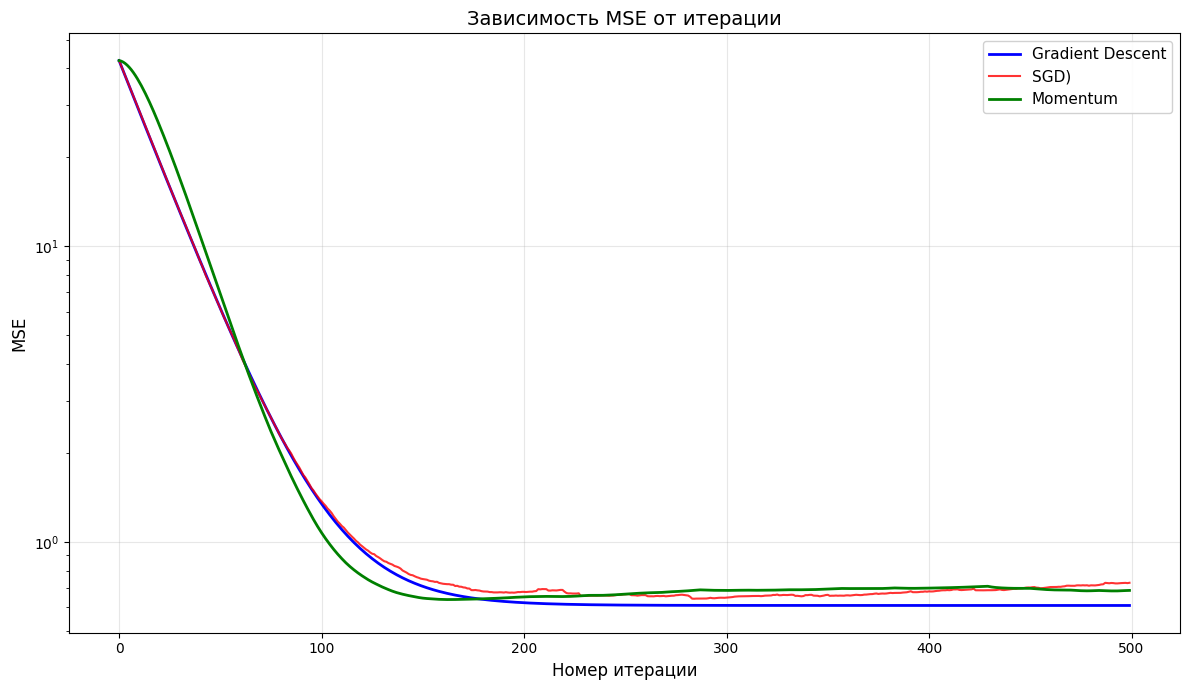

In [65]:
gd = GradientDescent(eta=0.01, max_iter=500, tolerance=1e-6)
gd.fit(X_train_scaled, y_train_log)

sgd = SGD(eta=0.01, max_iter=500, tolerance=1e-6, batch_size=32)
sgd.fit(X_train_scaled, y_train_log)

momentum = Momentum(eta=0.01, max_iter=500, tolerance=1e-6, batch_size=32, beta=0.9)
momentum.fit(X_train_scaled, y_train_log)

plt.figure(figsize=(12, 7))

plt.plot(gd.loss_history, label='Gradient Descent', color='blue', linewidth=2)
plt.plot(sgd.loss_history, label='SGD)', linewidth=1.5,  color='red', alpha=0.8)
plt.plot(momentum.loss_history, label='Momentum',  color='green', linewidth=2)

plt.title('Зависимость MSE от итерации', fontsize=14)
plt.xlabel('Номер итерации', fontsize=12)
plt.ylabel('MSE', fontsize=12)
plt.yscale('log')

plt.legend(loc='upper right', fontsize=11, framealpha=0.9)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Задание 10.1 $-$ бонус (0.5 балла). Уменьшающийся шаг для SGD

На графиках из задания 10 видно, что SGD с постоянным шагом не «успокаивается»: loss продолжает дёргаться вокруг минимума, потому что градиент по мини-батчу шумный. Популярный способ это исправить — постепенно **уменьшать шаг** по ходу обучения:

$$
\eta_t = \frac{\eta_0}{(t + 1)^{p}},
$$

где $t$ — номер итерации (с нуля), $\eta_0$ — начальный шаг, $p \geq 0$ — скорость уменьшения ($p = 0$ — обычный SGD с постоянным шагом).

1. Допишите класс `SGDDecay` ниже.
2. Обучите SGD с $p = 0$, $p = 0.5$ и $p = 1$ на данных из задания 8. Для каждого $p$ подберите свой $\eta_0$ по логарифмической сетке.
3. Нарисуйте кривые loss для лучших вариантов на одном графике и сравните итоговое качество на тесте (MSE и $R^2$).

*Подсказка:* при уменьшающемся шаге веса меняются всё медленнее, и критерий останова по `tolerance` может сработать слишком рано. Проверьте, не происходит ли этого у вас, и если да — учтите это (например, уменьшите `tolerance`).

In [67]:
class SGDDecay(SGD):
    """
    SGD с уменьшающимся шагом
    где t — номер итерации (с нуля).
    power = 0 — обычный SGD с постоянным шагом.
    """
    def __init__(self, eta=1e-2, max_iter=10000, tolerance=1e-6, w0=None, batch_size=1, power=0.5):
        super().__init__(eta, max_iter, tolerance, w0, batch_size)
        self.power = power

    def fit(self, X, y):
        if self.w0 is not None:
            self.w = self.w0.copy()
        else:
            self.w = np.zeros(X.shape[1])
        
        self.loss_history = []
        n_samples = X.shape[0]
        eta_0 = self.eta 

        for t in range(self.max_iter):
            loss = self.calc_loss(X, y)
            self.loss_history.append(loss)

            eta_t = eta_0 / ((t + 1) ** self.power)

            indices = np.random.choice(n_samples, self.batch_size, replace=False)
            X_batch = X[indices]
            y_batch = y[indices]

            grad = self.calc_gradient(X_batch, y_batch)
            w_new = self.w - eta_t * grad

            if np.linalg.norm(w_new - self.w) < self.tolerance and t > 100:
                self.w = w_new
                break
                
            self.w = w_new
          
        return self

In [68]:
# TODO: подберите eta для power = 0, 0.5, 1, постройте кривые loss на одном графике,
#       сравните MSE и R^2 на тесте

best_models = {}

for power in [0, 0.5, 1]:
    best_mse = float('inf')
    best_eta = None
    best_model = None
    
    for eta_0 in np.logspace(-3, 0, 7):
        model = SGDDecay(eta=eta_0, max_iter=1000, tolerance=1e-8, batch_size=32, power=power)
        model.fit(X_train_scaled, y_train_log)
        y_pred = model.predict(X_test_scaled)
        mse = calc_mse(y_test_log, y_pred)
        
        if mse < best_mse:
            best_mse = mse
            best_eta = eta_0
            best_model = model
    
    best_models[power] = best_model
    r2 = calc_r2(y_test_log, best_model.predict(X_test_scaled))
    print(f"p={power}")
    print(f"Лучший eta_0={best_eta}")
    print(f"MSE={best_mse}")
    print(f"R^2={r2}")
    print(f"Итераций={len(best_model.loss_history)}")


C:\TMP\ipykernel_24096\1302942119.py:27: RuntimeWarning: overflow encountered in square
  return np.mean(err ** 2)
C:\TMP\ipykernel_24096\1778927189.py:10: RuntimeWarning: overflow encountered in square
  return np.mean((y_true - y_pred) ** 2)


p=0
Лучший eta_0=0.0031622776601683794
MSE=0.5865357564667851
R^2=0.06847074151998744
Итераций=1000
p=0.5
Лучший eta_0=0.1
MSE=0.5874901629124755
R^2=0.06695496431656844
Итераций=1000
p=1
Лучший eta_0=1.0
MSE=0.5949429418208577
R^2=0.055118547638476345
Итераций=1000


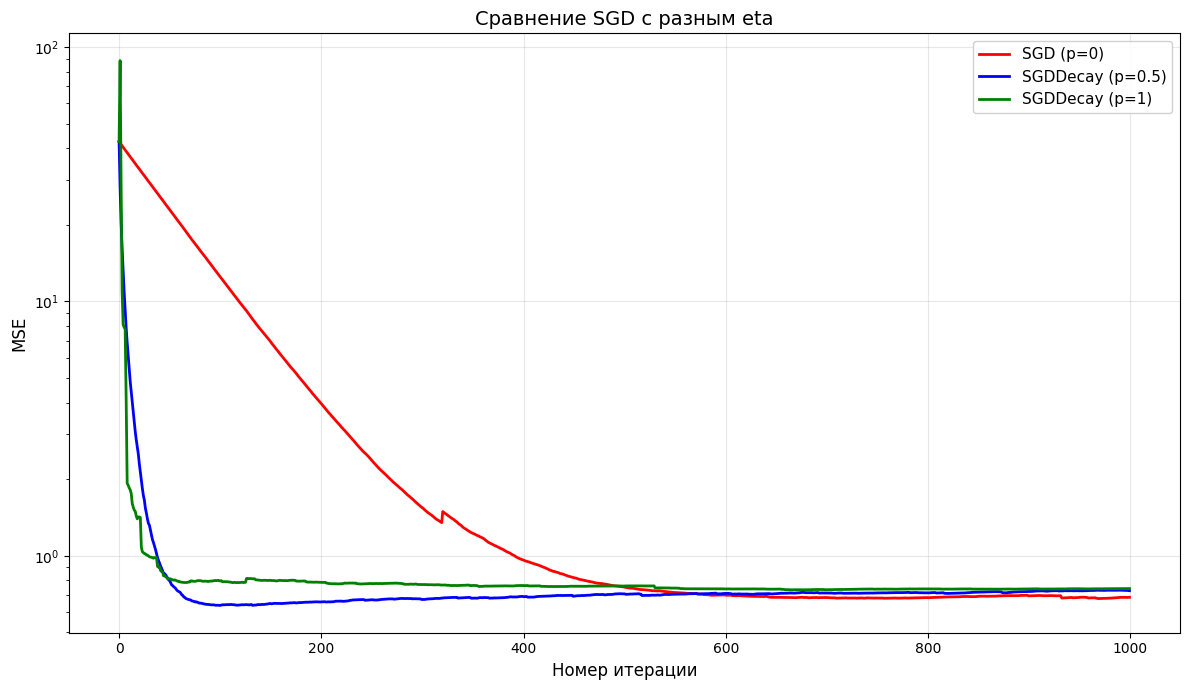

In [69]:
plt.figure(figsize=(12, 7))

plt.plot(best_models[0].loss_history, label='SGD (p=0)', color='red', linewidth=2)
plt.plot(best_models[0.5].loss_history, label='SGDDecay (p=0.5)', color='blue', linewidth=2)
plt.plot(best_models[1].loss_history, label='SGDDecay (p=1)', color='green', linewidth=2)

plt.title('Сравнение SGD с разным eta', fontsize=14)
plt.xlabel('Номер итерации', fontsize=12)
plt.ylabel('MSE', fontsize=12)
plt.yscale('log')

plt.legend(loc='upper right', fontsize=11, framealpha=0.9)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### **Вопрос:**

Для сходимости SGD к минимуму последовательность шагов $\eta_t$ должна удовлетворять **условиям Роббинса–Монро**. Сформулируйте их и объясните простыми словами, зачем нужно каждое из условий. Какие из ваших расписаний ($p = 0$, $p = 0.5$, $p = 1$) им удовлетворяют? Согласуется ли это с тем, что вы увидели на графиках?

**Ответ нейросети:**
**Условия Роббинса–Монро** гарантируют сходимость стохастического градиентного спуска (SGD) к истинному минимуму функции потерь в условиях случайного шума. 

Последовательность размеров шага (learning rate) \(\eta_t\) должна удовлетворять двум условиям:

1. **Расходимость ряда шагов:**
   \[\sum_{t=1}^{\infty} \eta_t = \infty\]

2. **Сходимость ряда квадратов шагов:**
   \[\sum_{t=1}^{\infty} \eta_t^2 < \infty\]

---

### Объяснение простыми словами

* **Зачем нужно первое условие (\(\sum \eta_t = \infty\))?**
  Это условие **гарантирует, что алгоритм сможет дойти до минимума**, как бы далеко от него он ни стартовал. Если бы этот ряд сходился (был конечным), суммарная длина всех возможных шагов алгоритма была бы ограничена. В таком случае SGD мог бы просто «застрять» по пути к минимуму, растратив весь запас длины шага, даже если градиент указывает верное направление. Алгоритму нужна «бесконечная батарейка», чтобы преодолеть любое расстояние.

* **Зачем нужно второе условие (\(\sum \eta_t^2 < \infty\))?**
  Это условие **гарантирует, что алгоритм не будет бесконечно блуждать вокруг минимума из-за случайного шума**. Поскольку в SGD градиент оценивается по мини-батчу или одному объекту, он всегда содержит шум (случайное отклонение от истинного градиента). Если шаги будут уменьшаться слишком медленно, этот шум будет постоянно выбрасывать алгоритм из точки минимума. Ограничение на сумму квадратов заставляет шаги затухать достаточно быстро, чтобы «гасить» случайные колебания и позволить алгоритму стабилизироваться (сойтись) в самой оптимальной точке.

---

### Анализ расписаний шага (\(\eta_t \propto \frac{1}{t^p}\))

Рассмотрим стандартный вид расписания шага \(\eta_t = \frac{C}{t^p}\) (где \(C > 0\) — константа) для трех предложенных вариантов \(p\):

| Расписание (\(p\)) | Выполнение 1-го условия (\(\sum \frac{1}{t^p} = \infty\)) | Выполнение 2-го условия (\(\sum \frac{1}{t^{2p}} < \infty\)) | Удовлетворяет условиям Роббинса–Монро? |
| :--- | :--- | :--- | :--- |
| **\(p = 0\)** (\(\eta_t = C\)) | **Да** (ряд \(1 + 1 + 1...\) расходится) | **Нет** (ряд \(1 + 1 + 1...\) расходится) | **Нет** (шаг постоянный, алгоритм будет вечно прыгать вокруг минимума из-за шума) |
| **\(p = 0.5\)** (\(\eta_t = \frac{C}{\sqrt{t}}\)) | **Да** (ряд расходится) | **Нет** (ряд квадратов превращается в гармонический \(\frac{1}{t}\), он расходится) | **Нет** (шаг затухает слишком медленно, шум всё еще будет раскачивать систему) |
| **\(p = 1\)** (\(\eta_t = \frac{C}{t}\)) | **Да** (гармонический ряд расходится) | **Да** (ряд квадратов \(\frac{1}{t^2}\) сходится) | **Да (Полностью удовлетворяет)** |

**Вывод:** Из трех вариантов только расписание с **\(p = 1\)** полностью удовлетворяет условиям Роббинса–Монро.

**Ваш ответ:**

Каждому из условий удовлетворяет p = 1, в остальных модель будет либо скакать вокруг минимума либо не гарантировать полную сходиость.

### Задание $-$ бонус (0.25 балла).
Реализуйте линейную регрессию с функцией потерь MSE, обучаемую с помощью метода
[Adam](https://arxiv.org/pdf/1412.6980.pdf) $-$ добавьте при необходимости параметры в класс модели, повторите предыдущие два пункта и сравните результаты.

In [70]:
class Adam(SGD):
    def __init__(self, eta=1e-3, max_iter=10000, tolerance=1e-6, w0=None, batch_size=32, 
                 beta1=0.9, beta2=0.999, epsilon=1e-8):
        super().__init__(eta, max_iter, tolerance, w0, batch_size)
        self.beta1 = beta1
        self.beta2 = beta2
        self.epsilon = epsilon

    def fit(self, X, y):
        if self.w0 is not None:
            self.w = self.w0.copy()
        else:
            self.w = np.zeros(X.shape[1])
            
        self.loss_history = []
        n_samples = X.shape[0]
        
        m = np.zeros_like(self.w) # среднее градиентов, как в Momentum
        v = np.zeros_like(self.w) # дисперсия градиентов

        for t in range(1, self.max_iter + 1):
            loss = self.calc_loss(X, y)
            self.loss_history.append(loss)

            indices = np.random.choice(n_samples, self.batch_size, replace=False)
            X_batch = X[indices]
            y_batch = y[indices]

            g = self.calc_gradient(X_batch, y_batch)

            # инерция и адаптивность обновление
            m = self.beta1 * m + (1 - self.beta1) * g
            v = self.beta2 * v + (1 - self.beta2) * (g ** 2)

            # коррекция смещения
            m_hat = m / (1 - self.beta1 ** t)
            v_hat = v / (1 - self.beta2 ** t)

            # обновление весов
            w_new = self.w - self.eta * m_hat / (np.sqrt(v_hat) + self.epsilon)

            # чтобы модель не убежала восвояси
            if np.linalg.norm(w_new - self.w) < self.tolerance:
                self.w = w_new
                break
                
            self.w = w_new

        return self

In [72]:
adam = Adam(eta=0.01, max_iter=1000, tolerance=1e-8, batch_size=32)
adam.fit(X_train_scaled, y_train_log)

sgd_decay = SGDDecay(eta=0.1, max_iter=1000, tolerance=1e-8, batch_size=32, power=0.5)
sgd_decay.fit(X_train_scaled, y_train_log)

momentum = Momentum(eta=0.01, max_iter=1000, tolerance=1e-8, batch_size=32, beta=0.9)
momentum.fit(X_train_scaled, y_train_log)


y_pred_adam = adam.predict(X_test_scaled)
mse_adam = calc_mse(y_test_log, y_pred_adam)
r2_adam = calc_r2(y_test_log, y_pred_adam)

print("Adam")
print(f"eta={adam.eta}")
print(f"MSE={mse_adam}")
print(f"R^2={r2_adam}")
print(f"Итераций={len(adam.loss_history)}")

y_pred_decay = sgd_decay.predict(X_test_scaled)
mse_decay = calc_mse(y_test_log, y_pred_decay)
r2_decay = calc_r2(y_test_log, y_pred_decay)

print("SGDDecay(p=0,5)")
print(f"eta_0={sgd_decay.eta}")
print(f"MSE={mse_decay}")
print(f"R^2={r2_decay}")
print(f"Итераций={len(sgd_decay.loss_history)}")

y_pred_mom = momentum.predict(X_test_scaled)
mse_mom = calc_mse(y_test_log, y_pred_mom)
r2_mom = calc_r2(y_test_log, y_pred_mom)

print(f"eta={momentum.eta}")
print(f"MSE={mse_mom}")
print(f"R^2={r2_mom}")
print(f"Итераций={len(momentum.loss_history)}")

Adam
eta=0.01
MSE=0.8811781719063176
R^2=-0.3994769117049535
Итераций=1000
SGDDecay(p=0,5)
eta_0=0.1
MSE=0.5866454451155376
R^2=0.06829653528531288
Итераций=1000
eta=0.01
MSE=0.5906594093731482
R^2=0.061921603992153074
Итераций=1000


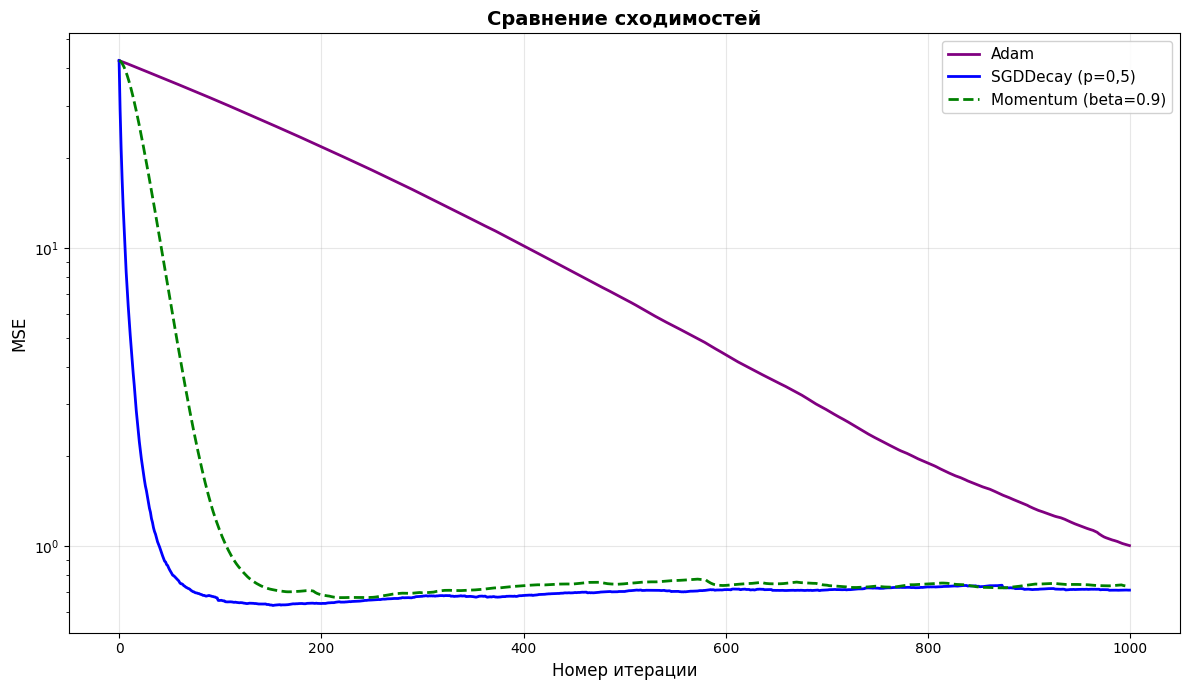

In [73]:
plt.figure(figsize=(12, 7))

plt.plot(adam.loss_history, label='Adam', color='purple', linewidth=2)
plt.plot(sgd_decay.loss_history, label='SGDDecay (p=0,5)', color='blue', linewidth=2)
plt.plot(momentum.loss_history, label='Momentum (beta=0.9)', color='green', linewidth=2, linestyle='--')

plt.title('Сравнение сходимостей', fontsize=14, fontweight='bold')
plt.xlabel('Номер итерации', fontsize=12)
plt.ylabel('MSE', fontsize=12)
plt.yscale('log')

plt.legend(loc='upper right', fontsize=11, framealpha=0.9)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Часть 2. Знакомство с PyTorch (4 балла)

**PyTorch** — самая популярная библиотека для обучения нейросетей. С ней мы будем работать весь курс. Главное, что она умеет:

- работать с многомерными массивами — **тензорами** (`torch.Tensor`). Они очень похожи на `numpy.ndarray`, но умеют считаться на видеокарте;
- **автоматически считать производные** (autograd). В первой части вы выводили градиенты руками — PyTorch делает это сам.

Ключевые идеи autograd:

- `requires_grad=True` — просим PyTorch запоминать операции с тензором, чтобы потом посчитать производную по нему;
- `y.backward()` — посчитать производные скалярного значения `y` по всем тензорам с `requires_grad=True`; результат попадёт в их атрибут `.grad`;
- `with torch.no_grad():` — временно отключаем запоминание операций (нужно, например, когда мы сами обновляем параметры).

**Ссылки, которые могут оказаться полезными:**

- Официальный туториал PyTorch: https://pytorch.org/tutorials/beginner/basics/intro.html
- Туториал по autograd: https://pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html

### Задание 11 (0.5 балла). Тензоры

Выполните по шагам (каждый шаг — одна-две строчки кода, выводите результат через `print`):

1. Создайте тензор `a` из списка `[[1, 2, 3], [4, 5, 6]]` с типом `torch.float32`, выведите его форму (`shape`) и тип (`dtype`);
2. Создайте тензор `b` размера $3 \times 2$ из случайных чисел (`torch.randn`);
3. Посчитайте матричное произведение `a` и `b` (оператор `@`) и поэлементное произведение `a` на само себя (`*`);
4. Посчитайте сумму и среднее `a` по строкам (аргумент `dim`);
5. Переведите `a` в numpy-массив и обратно (`.numpy()`, `torch.from_numpy`);
6. Измените форму `a` на $3 \times 2$ (`reshape`).

In [94]:
import torch
import numpy as np

a = torch.tensor([[1, 2, 3], [4, 5, 6]], dtype=torch.float32)
print("a=",a)
print(f"shape: {a.shape}")
print(f"dtype: {a.dtype}\n")

b = torch.randn(3,2)
print("b=",b, "\n")

print(f" матричное произведение a и b={a @ b}")
print(f"поэлементное произведение a на само себя={a*a}\n")

print(f"Сумма a строкам = {a.sum(dim=1)}")
print(f"Среднее a по строкам = {a.mean(dim=1)}\n")

a_num = a.numpy()
print(f"numpy массив {a_num}")
print(f"обратно {torch.from_numpy(a_num)}\n")

a_shaped = a.reshape(3, 2)
print(f"a shaped= {a_shaped}")

a= tensor([[1., 2., 3.],
        [4., 5., 6.]])
shape: torch.Size([2, 3])
dtype: torch.float32

b= tensor([[-0.5089,  0.0809],
        [-0.2667, -1.1657],
        [-1.5891,  0.3734]]) 

 матричное произведение a и b=tensor([[ -5.8097,  -1.1303],
        [-12.9039,  -3.2645]])
поэлементное произведение a на само себя=tensor([[ 1.,  4.,  9.],
        [16., 25., 36.]])

Сумма a строкам = tensor([ 6., 15.])
Среднее a по строкам = tensor([2., 5.])

numpy массив [[1. 2. 3.]
 [4. 5. 6.]]
обратно tensor([[1., 2., 3.],
        [4., 5., 6.]])

a shaped= tensor([[1., 2.],
        [3., 4.],
        [5., 6.]])


### Задание 12 (1 балл). Autograd

1. Возьмите функцию $f(x) = x^2 - 30x + 1$ из первой части. Создайте тензор `x` со значением `5.0` и `requires_grad=True`, посчитайте `y = f(x)`, вызовите `y.backward()` и выведите `x.grad`. Совпадает ли результат с производной, которую вы нашли в задании 2?
2. Проверьте формулу градиента MSE, которую вы выводили в первой части: $\nabla_w Q = \dfrac{-2}{\ell} X^T (y - Xw)$. Для этого посчитайте MSE на данных из ячейки ниже, вызовите `backward()` и сравните `w.grad` с градиентом, посчитанным по формуле (используйте `torch.allclose`).

In [104]:
# 1. Производная f(x) = x^2 - 30x + 1 в точке x = 5

x = torch.tensor(5.0, requires_grad=True)
y = x**2 - 30*x + 1
y.backward()

print(f"При {x}, f(x) = {y}") 
print(x.grad)

При 5.0, f(x) = -124.0
tensor(-20.)


In [105]:
# 2. Проверяем формулу градиента MSE
torch.manual_seed(0)
X = torch.randn(100, 3)
y = torch.randn(100)
w = torch.randn(3, requires_grad=True)


# TODO: посчитайте MSE
y_pred = X @ w
err = y - y_pred
mse = (err ** 2).mean()
# TODO: посчитайте градиент по формуле из первой части
mse.backward()
grad_autograd = w.grad.clone()
# TODO: сравните его с w.grad через torch.allclose
ell = X.shape[0]
grad_formula = (-2 / ell) * X.T @ (y - X @ w)


print(f"Градиент autograd={grad_autograd}")
print(f"Градиент по формуле={grad_formula}")
print(f"Совпадение {torch.allclose(grad_autograd, grad_formula)}")

Градиент autograd=tensor([-1.3756,  1.1534,  4.4033])
Градиент по формуле=tensor([-1.3756,  1.1534,  4.4033], grad_fn=<MvBackward0>)
Совпадение True


### **Вопрос:**

Посчитайте `y = f(x)` и вызовите `y.backward()` два раза подряд (каждый раз заново вычисляя `y`), не обнуляя градиент. Что стало с `x.grad`? Почему в циклах обучения градиенты нужно обнулять на каждом шаге?

**Ответ нейросети:**

Когда вы вычисляете y = f(x) и дважды вызываете .backward() подряд (каждый раз заново вычисляя y) без обнуления градиентов, значение x.grad увеличится в два раза (оно станет равным сумме градиентов от обеих итераций).
```
**Ваш ответ:**
Если не обновлять то pytorch будет их накапливать их.

In [107]:
x = torch.tensor(5.0, requires_grad=True)
y = x**2 - 30*x + 1
y.backward()
print(x.grad)

y = x**2 - 30*x + 1
y.backward()
print(x.grad)

tensor(-20.)
tensor(-40.)


### Задание 13 (1 балл). Градиентный спуск через autograd

Перепишите градиентный спуск из задания 4 так, чтобы производную считал PyTorch, а не sympy. Запустите его для функций $f$ и $g$ из первой части с теми же начальными точками и `learning_rate`, что и в задании 5, и сравните результаты: совпадает ли найденная точка и число итераций?

In [117]:
def gradient_descent_torch(f, x_start, learning_rate, epsilon=1e-6, num_iterations=1000):
    """
    f — функция, которая принимает и возвращает torch-тензор (например, lambda t: t**2 - 30*t + 1)
    Возвращает: (найденная точка (float), траектория — список float)
    """
    x = torch.tensor(float(x_start), requires_grad=True)
    trace = [x.item()]

    for i in range(num_iterations):
        # TODO: вычислите значение функции 
        y = f(x)
        # TODO: посчитайте производную 
        y.backward()
        
        grad_value = x.grad.item()
        
        if abs(x.grad.item()) < 1e-3:  
            break
        # TODO: сделайте шаг градиентного спуска внутри блока без градиентов
        with torch.no_grad():
            x_new = x - learning_rate * x.grad

            if abs(x_new.item() - x.item()) < epsilon:
                x = x_new
                trace.append(x.item())
                break
                
        # TODO: обнулите градиент:
        x.grad.zero_()
        # TODO: добавьте x.item() в trace и остановитесь, если условие остановки
        x = x_new.detach().requires_grad_(True)
        trace.append(x.item())
        

    return x.item(), trace

In [121]:
# TODO: запустите gradient_descent_torch для f и g, сравните с результатами задания 5
epsilon = 1e-6
delta = 1e-3
num_iterations = 1000

x_start_f = random.uniform(0, 25)
lr_f = 0.1

f_torch = lambda t: t**2 - 30*t + 1
x_found_torch, trace_torch = gradient_descent_torch(f_torch, x_start_f, lr_f, epsilon, num_iterations)

print(f"f(x) = x^2 - 30x + 1")
print(f"x_start = {x_start_f}, learning_rate = {lr_f}")
print(f"Найдено: x = {x_found_torch}, f(x) = {f_torch(torch.tensor(x_found_torch)).item():.4f}")
print(f"Итераций: {len(trace_torch)}")


x_start_g = random.uniform(-8, -2)
lr_g = 0.01

g_torch = lambda t: -t**3 - 7*t**2 + 5*t + 17
x_found_torch_g, trace_torch_g = gradient_descent_torch(g_torch, x_start_g, lr_g, epsilon, num_iterations)

print(f"g(x) = -x^3 - 7x^2 + 5x + 17")
print(f"x_start = {x_start_g}, learning_rate = {lr_g}")
print(f"Найдено: x = {x_found_torch_g}, g(x) = {g_torch(torch.tensor(x_found_torch_g)).item()}")
print(f"Итераций: {len(trace_torch_g)}")
print("Найденный x и кол-во итераций почти идентичны, так как методы используют одинаковую математику")

f(x) = x^2 - 30x + 1
x_start = 7.123849092102283, learning_rate = 0.1
Найдено: x = 14.999570846557617, f(x) = -224.0000
Итераций: 45
g(x) = -x^3 - 7x^2 + 5x + 17
x_start = -3.4690939115974544, learning_rate = 0.01
Найдено: x = -4.999944686889648, g(x) = -58.0
Итераций: 62


### **Вопрос:**

Зачем при обновлении `x` нужен `with torch.no_grad()`? Что будет, если его убрать?

**Ответ нейросети:**

PyTorch начнет отслеживать саму операцию шага градиентного спуска (x = x - lr * x.grad). Вместо обычного изменения числа, это действие станет частью графа вычислений (Computational Graph). На следующем шаге PyTorch попытается взять производную от самой производной, что приведет к неверным расчетам.


**Ваш ответ:**
Если начать цикл без этого условия то у нас неправильно посчитаются градиенты.

### Задание 14 (1.5 балла). Линейная регрессия на PyTorch

Теперь обучим ту же линейную регрессию, что и в задании 7, но «по-взрослому» — стандартными средствами PyTorch:

- модель — линейный слой `nn.Linear`;
- функция потерь — `nn.MSELoss`;
- оптимизатор — `torch.optim.SGD`.

Именно такой цикл обучения (обнулить градиенты → прогноз → loss → `backward()` → шаг оптимизатора) вы будете писать во всех следующих ДЗ.

Что нужно сделать:
1. Используйте данные такси из задания 8. `nn.Linear` сам добавляет свободный член, поэтому столбец из единиц здесь не нужен (уберите его или создайте слой с `bias=False`);
2. Допишите цикл обучения ниже и обучите модель (на каждой итерации используем всю обучающую выборку — это полный градиентный спуск);
3. Нарисуйте график loss по итерациям, посчитайте MSE и $R^2$ на тесте и сравните с вашей реализацией из задания 9;
4. Замените `torch.optim.SGD` на `torch.optim.Adam` (подберите `lr`) и сравните скорость сходимости.

In [124]:
import torch.nn as nn

# TODO: переведите данные из задания 8 в тензоры типа float32
#       целевую переменную сделайте формы (N, 1), чтобы она совпадала по форме с выходом модели
X_train_t = torch.tensor(X_train_scaled[:, 1:], dtype=torch.float32)
y_train_t = torch.tensor(y_train_log, dtype=torch.float32).reshape(-1, 1)
X_test_t = torch.tensor(X_test_scaled[:, 1:], dtype=torch.float32)
y_test_t = torch.tensor(y_test_log, dtype=torch.float32).reshape(-1, 1)

model = nn.Linear(X_train_t.shape[1], 1)  # TODO: число признаков
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)  # TODO: подберите lr

num_epochs = 1000 # TODO
loss_history = []

for epoch in range(num_epochs):
    # TODO: 1) обнулите градиенты
    optimizer.zero_grad()
    # TODO: 2) прямой проход
    y_pred = model(X_train_t)
    # TODO: 3) посчитайте loss
    loss = criterion(y_pred, y_train_t)
    # TODO: 4) обратный проход
    loss.backward()
    # TODO: 5) шаг оптимизатора
    optimizer.step()
    # TODO: 6) сохраните
    loss_history.append(loss.item())

In [129]:
model_adam = nn.Linear(X_train_t.shape[1], 1)
optimizer_adam = torch.optim.Adam(model_adam.parameters(), lr=0.1)

loss_history_adam = []
for epoch in range(num_epochs):
    optimizer_adam.zero_grad()
    loss = criterion(model_adam(X_train_t), y_train_t)
    loss.backward()
    optimizer_adam.step()
    loss_history_adam.append(loss.item())

with torch.no_grad():
    y_pred_sgd_t = model(X_test_t).numpy().flatten()
    y_pred_adam_t = model_adam(X_test_t).numpy().flatten()

print("PyTorch SGD:")
print(f"MSE={calc_mse(y_test_log, y_pred_sgd_t)}")
print(f"R2={calc_r2(y_test_log, y_pred_sgd_t)} \n")
print("PyTorch Adam:")
print(f"MSE={calc_mse(y_test_log, y_pred_adam_t)}")
print(f"R2={calc_r2(y_test_log, y_pred_adam_t)} \n")

print("Своя реализация GradientDescent:")
print(f"MSE={calc_mse(y_test_log, gd.predict(X_test_scaled))}")
print(f"R2={calc_r2(y_test_log, gd.predict(X_test_scaled))} \n")
print("Своя реализация Adam:")
print(f"MSE={calc_mse(y_test_log, adam.predict(X_test_scaled))}")
print(f"R2={calc_r2(y_test_log, adam.predict(X_test_scaled))}")

PyTorch SGD:
MSE=0.6003687758134443
R2=0.04650130127280472 

PyTorch Adam:
MSE=0.6003853114153602
R2=0.04647503962239141 

Своя реализация GradientDescent:
MSE=0.6004481322959869
R2=0.04637526823130045 

Своя реализация Adam:
MSE=0.8811781719063176
R2=-0.3994769117049535


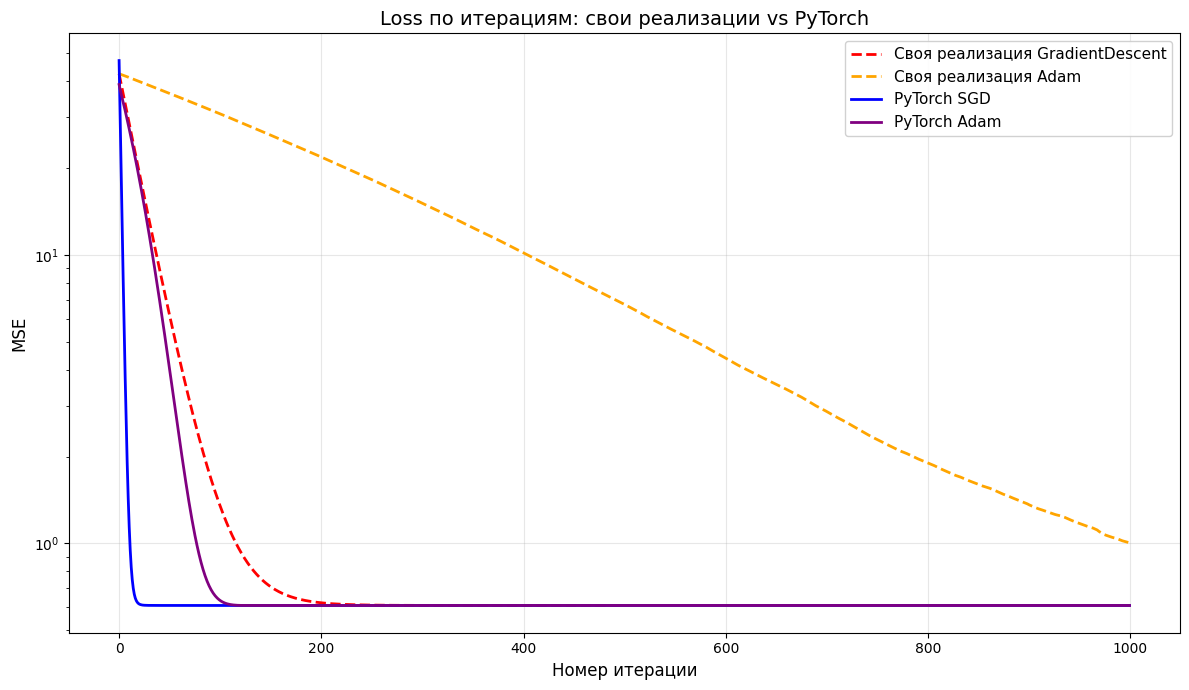

In [130]:
plt.figure(figsize=(12, 7))
plt.plot(gd.loss_history, label='Своя реализация GradientDescent', color='red', linestyle='--', linewidth=2)
plt.plot(adam.loss_history, label='Своя реализация Adam', color='orange', linestyle='--', linewidth=2)
plt.plot(loss_history, label='PyTorch SGD', color='blue', linewidth=2)
plt.plot(loss_history_adam, label='PyTorch Adam', color='purple', linewidth=2)
plt.title('Loss по итерациям: свои реализации vs PyTorch', fontsize=14)
plt.xlabel('Номер итерации', fontsize=12)
plt.ylabel('MSE', fontsize=12)
plt.yscale('log')
plt.legend(loc='upper right', fontsize=11, framealpha=0.9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### **Вопрос:**

Сопоставьте строчки цикла обучения на PyTorch с тем, что вы писали руками в задании 7. Какая строчка заменяет вычисление градиента? Какая — шаг по антиградиенту? Что делает оптимизатор и почему в вашей реализации из задания 7 такого шага не было?

**Ответ нейросети:**

Подробное сопоставление


В стандартном цикле обучения на PyTorch за вычисление градиентов и шаг по антиградиенту отвечают следующие строчки:
• Вычисление градиента: Заменяет строчка loss.backward().
• Шаг по антиградиенту: Заменяет строчка optimizer.step().

**Ваш ответ:**
Вычисление градента заменяется просто уже в модели err = y - X @ self.w, шаг по антиградиенту: w_new = self.w - self.eta * grad; self.w = w_new, оптимизатор хранит параметры модели а до этого внутри функции fit писали обновление весов.

## Использованные источники

Если вы пользовались чужими решениями, статьями, ответами на форумах и т.п. — перечислите ссылки здесь.

- ...

## Поздравляем, вы прошли игру!
╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ